# Chamley–Judd の「資本課税ゼロが望ましい」という議論を否定する
## ―― 楔(くさび)の帳簿の付け方と、ラムゼイ・モデルへの回帰

* 文責: JRF (Author)
* 協力: Claude Opus 5.5 (Anthropic) ―― 定式化・Lean による証明・シミュレーション・文献整理を大きく補った。
* 版: 0.3.0 (2026-10-14)

このノートブックは、Python による数値計算と、Lean 4 + Mathlib による定理の形式証明を含む。
本文中の「§1」〜「§4」は Lean ファイル `CJ_formula.lean` の節を指す(ノートブックの節は「第 n 節」「6.2 節」のように書く)。
Lean のソースは各所の `%%writefile` セルで `CJ_formula.lean` に書き出し、**最後にまとめて検証**する
(Google Colab でも、ローカルでも動くようにしてある)。

## 要旨

蓮見 亮『動学マクロ経済学へのいざない』(2020) 第3章は、税のあるラムゼイ・モデルを使って
「税収が足りないなら、資本所得税より消費税を上げる方が望ましい」と結論する。
これは Chamley (1986)・Judd (1985) の「長期的には資本所得税はゼロが最適」という命題の、教科書的な簡易版である。

本稿の主張は次のとおり。

1. **(再現)** 蓮見モデルでは、一定の消費税は定常状態に一切影響しない(労働供給が非弾力的なので、事実上の一括税になる)。
   一方、資本課税は定常資本 $K^{\ast}$ と定常消費 $C^{\ast}$ を厳密に下げる。家計のオイラー方程式とラムゼイ計画者の修正黄金律を並べれば、
   $\tau_k = 0$ が出る。予算制約 (3.2) からオイラー方程式 (3.12) を導く部分も含め、これらを Lean で証明する(§1–§2)。
   なお、一括税 $\tau_{h,t}$ はこの導出で消える。
2. **(JRF の変形)** 二つの変形を入れる。
   (1) 消費税が資本の収益を変えること:$A \mapsto A/(1+\tau_c)^b$。向きは二通りありうるとし、確定しない。
   $b<0$ は「消費税が、消費に比べて資本を持つことを有利にする」(非課税の資本サービス、蓄積そのものの動機(AI)、既存資本の再評価)、
   $b>0$ は「消費税が、貯蓄 1 単位で買える実物の資本を減らす」(硬直的な物価上昇の誘導形、資本財への課税)である。
   (2) 公共投資 $\gamma r K$ が資本の持ち主に比例して戻ること。
   ラムゼイ配分を再現する資本税率(基準 A)は
   $$\tau_k^\dagger = 1 + \gamma - (1+\tau_c)^b$$
   となる。**資本税率は消費税率と公共投資に「からめて」決まり、$b \ne 0$ なら一般にゼロではない。**
   * **$b<0$**:$\gamma = 0$ でも $\tau_k^\dagger > 0$ で、$\tau_c$ とともに増える。「消費税を上げるなら資本課税も上げるべき」である。これが JRF の本来の主張である。
   * **$b>0$**:基準 A では $\tau_k^\dagger<0$ だが、税収中立のもとで生涯厚生を最大にする税率(基準 B)は $\tau_k^{\ast} > 0$ になる。
     さらに $\gamma > (1+\tau_c)^b - 1$ なら基準 A でも正、$\gamma = \tau_k$ なら結論が逆転し、消費税は上げない方がよくなる。
   * **どちらの符号でも、少なくとも一方の基準で資本課税は正になる。** $\tau_k=0$ が両方の基準で最適になるのは $b=0,\ \gamma=0$ のときだけである。
   * **政策含意**:必需品への課税が賃金圧力を生むなら、必需品への課税ほど $|b|$ が大きい。
     そのとき**食料品減税は、$b$ の符号にかかわらず $K^{\ast}$ をラムゼイの値に近づける**。
     $b>0$ では実物の資本を減らさず、$b<0$ では過剰な資本蓄積を抑え、必要な資本税率も下げる。
   いずれも §3 で Lean により証明する。
3. **(ラムゼイへの回帰)** 予算制約 (3.2) に政府支出 $g_t$ を足し戻すと、税率が恒等的に消えて、
   ラムゼイ・モデル (2.28) にそのまま戻る(§4、Lean で証明)。
   Chamley–Judd の長期の目標配分とは、まさにこのラムゼイ・モデルの修正黄金律である。
   (1)(2) を入れても、政府消費 $g_t$ を足し戻せば税の楔はすべて消える。ただし $b>0$ の実物の損失だけは技術の側に残る。
   これは**帳簿の付け方では消えない楔**であり、JRF の (1) の強みになる。
4. **(結論)** 「どの税が楔を生むか」は、モデルの中で税と還元を**どう帳簿に付けるか**で決まる。
   その付け方を真の世界(ラムゼイ・モデル)が一意に決めることはない。
   JRF の変形が恣意的だとすれば、Chamley–Judd 型の財政モデルも同じ程度に恣意的である。
   したがって「資本課税ゼロ」はモデルの頑健な帰結とは言えない。
   同じことは JRF の本来の主張($b<0$ で資本課税が正)にも当てはまる。帳簿の付け方で消えないのは、$b>0$ の実物の損失に乗った結論(消費税は中立でなく、食料品減税が有効)だけである。

数値面でも、生涯厚生を基準にして税収中立な最適税率の組合せを求めると、
蓮見モデル ($b=0$) では $\tau_k^{\ast} \approx 0$(Chamley–Judd の再現)、
$b<0$ では $\tau_k^{\ast} > 0$ で基準 A の $\tau_k^\dagger$ とほぼ一致し、$b>0$ では $\tau_k^{\ast} \approx b > 0$ となった(6.2 節)。
食料品減税についても、税収を一定に保ったまま食料品の税率を下げると、どちらの符号でも生涯厚生が上がる例を示す(6.4 節)。

なお、Gemini との過去の対話(2025)の結論の一つ「$b=0$ で $\gamma$ だけを入れても、消費税の引き上げは厚生を悪化させる」は、蓮見モデルの枠内では成り立たない。
$b=0,\ \gamma=\tau_k$ では両税とも定常状態に中立になる(`jrf2_only_neutral`)。
「言えなくなると思っていた」という JRF の当初の直観の方が正しかった。

## 1. 背景・過去の議論・参考文献

### この議論の出発点(JRF の過去の議論)

* JRF「資本家に有利すぎる財政モデルを批判する。蓮見 亮『動学マクロ経済学へのいざない』...」『JRF のひとこと』2022-06-02.
  http://jrf.cocolog-nifty.com/statuses/2022/06/post-3e0e5b.html
  ―― 本稿で扱う批判 (1)(2) と「$g_t$ を足すとラムゼイ・モデル (2.28) に戻る」という指摘の原文。
* JRF「蓮見 亮『動学マクロ経済学へのいざない』第3章「財政モデル: 税制と経済成長」の検算と批判」(dynamic_macro_economics_03.ipynb), GitHub Gist, 2022.
  https://gist.github.com/JRF-2018/e59fff66621f93f4e5f832aef9922720
  ―― 本の R ソースを Python で検算し、(1)(2) を入れた定常状態を数値で見たもの。
  そこでは「$b=1$ とすると、$\tau_c$ と $\tau_k$ のどちらを上げるのがよいかは $C$ と $K$ のどちらを重視するかで変わり、どちらがいいとは言えない」となっていた。
  本稿は、この判断基準を生涯厚生にそろえ、税収を中立にして、決着を付け直す試みでもある。
* JRF「資本課税についての議論 with Gemini 2.5 Flash」2025-05-19. 共有リンク https://gemini.google.com/share/79de6ebd30fb
  共有ページは AI からは読めないことがあるため、ログを Markdown で公開している:
  https://github.com/JRF-2018/misc_ipynb/blob/master/gemini_conversation-20250519.md 。主な内容は次のとおり。
  * Chamley–Judd の連続時間版の説明。家計 $(1-\tau_k)r^{\ast} = \rho$ (\*\*) と計画者 $r^{\ast}=\rho$ (\*\*\*) から $\tau_k^{\ast}=0$ を出す。
  * JRF の問題意識。AI は資本なので、資本蓄積を最優先すると「AI だけが成長し、人間はいらない・少子化でよい」となりかねない。
    一定の消費、つまり人間の生きる余地を守るには、資本課税も一定程度必要ではないか。Kaldor の支出税論にも触れている。
  * JRF による (1) の再説明。消費税の分だけ賃金を上げる必要があり、物価は消費税分以上に上がる。
    すると、蓄積済みの資本の価値が上がり、価格で見て、より少ない資本で生産できる。
  * Gemini による改造 Chamley–Judd の導出。$(1-\tau_k)\,r^{\ast}(1+\tau_c)^b = \rho$ から $\tau_k^{\ast} = 1 - 1/(1+\tau_c)^b$ を出し、
    $\gamma$ を入れて $\tau_k^{\ast} = 1 + \gamma - 1/(1+\tau_c)^b$ を得ている。
    $b = 0$ では $\tau_k^{\ast} = \gamma$ となる。
  
  この対話の時点では、(1) の $b$ の意味が確定しておらず、Gemini の定式化 $r(1+\tau_c)^b$ は本稿の $b<0$ に当たる。
  本稿では第 4 節 (1) で、$b<0$(消費税が資本を持つことを有利にする)と $b>0$(貯蓄 1 単位で買える実物の資本が減る)を区別し、
  それぞれの理由と帰結を示す。Gemini の式 $\tau_k^{\ast} = 1 - 1/(1+\tau_c)^b$ は、本稿の楔定理の $b<0$ の場合にそのまま当たる。
  一方、Gemini の最後の回答「$b=0$ でも消費税の引き上げは厚生を悪化させる」は、労働供給の歪みを暗に仮定しており、蓮見モデルでは成り立たない(要旨の注を参照)。

### 原典・関連文献

(書誌は Claude の知識にもとづく。Guerreiro–Rebelo–Teles (2022)、Costinot–Werning (2023)、Ljungqvist–Sargent (2018)、スミス、リカードの該当章はウェブ検索で確認済み。その他は原典での確認を推奨する。)

* 蓮見 亮 (2020)『動学マクロ経済学へのいざない』日本評論社。特に第3章「財政モデル: 税制と経済成長」。
  サポートページ https://www.rhasumi.net/wiki/wiki.cgi?page=dynamicmodels ,
  ソース https://github.com/rhasumi/dynamicmodels/blob/master/ch3/Ramsey_tax.R
* Smith, A. (1776) *An Inquiry into the Nature and Causes of the Wealth of Nations*, Book V, Chapter 2, Article IV "Taxes upon Consumable Commodities".
  ―― 必需品への課税は、賃金を引き上げるか労働需要を減らす。
* Ricardo, D. (1817; 3rd ed. 1821) *On the Principles of Political Economy and Taxation*, Chapter 16 "Taxes on Wages".
  ―― 賃金への課税はすべて利潤への課税であり、必需品への課税は一部が利潤への課税である。
* Ljungqvist, L. and T. J. Sargent (2018) *Recursive Macroeconomic Theory*, 4th ed., MIT Press. Chapter 11 "Fiscal Policies in a Growth Model". ―― 蓮見 (2020) 第3章のモデルが参考にした章。
* Chamley, C. (1986) "Optimal Taxation of Capital Income in General Equilibrium with Infinite Lives," *Econometrica* 54(3), 607–622.
* Judd, K. L. (1985) "Redistributive Taxation in a Simple Perfect Foresight Model," *Journal of Public Economics* 28(1), 59–83.
* Atkinson, A. B. and J. E. Stiglitz (1976) "The Design of Tax Structure: Direct versus Indirect Taxation," *Journal of Public Economics* 6, 55–75.
* Diamond, P. and J. Mirrlees (1971) "Optimal Taxation and Public Production I: Production Efficiency," *American Economic Review* 61(1), 8–27.
* Barro, R. J. (1990) "Government Spending in a Simple Model of Endogenous Growth," *Journal of Political Economy* 98(5), S103–S125.
  ―― 生産的な政府支出があると、最適な所得(資本)課税率は正になる。JRF の (2) と同じ方向の古典。
* Correia, I. H. (1996) "Should Capital Income Be Taxed in the Steady State?" *Journal of Public Economics* 60(1), 147–151.
  ―― 課税できない生産要素があると、定常状態の資本課税はゼロでなくなる。
* Aiyagari, S. R. (1995) "Optimal Capital Income Taxation with Incomplete Markets, Borrowing Constraints, and Constant Discounting," *Journal of Political Economy* 103(6), 1158–1175.
* Lansing, K. J. (1999) "Optimal Redistributive Capital Taxation in a Neoclassical Growth Model," *Journal of Public Economics* 73(3), 423–453.
* Chari, V. V. and P. J. Kehoe (1999) "Optimal Fiscal and Monetary Policy," in *Handbook of Macroeconomics* Vol. 1C, ch. 26.
* Conesa, J. C., S. Kitao and D. Krueger (2009) "Taxing Capital? Not a Bad Idea After All!" *American Economic Review* 99(1), 25–48.
* Straub, L. and I. Werning (2020) "Positive Long-Run Capital Taxation: Chamley–Judd Revisited," *American Economic Review* 110(1), 86–119.
  ―― Chamley–Judd モデルの内部でも、長期の資本課税がゼロに収束しない場合があることを示した。
* Chari, V. V., J. P. Nicolini and P. Teles (2020) "Optimal Capital Taxation Revisited," *Journal of Monetary Economics* 116, 147–165.
* Guerreiro, J., S. Rebelo and P. Teles (2022) "Should Robots Be Taxed?" *Review of Economic Studies* 89(1), 279–311. doi:10.1093/restud/rdab019
  ―― 定型業務の労働者が労働市場に残っているあいだは、ロボットへの課税が最適になる。
* Costinot, A. and I. Werning (2023) "Robots, Trade, and Luddism: A Sufficient Statistic Approach to Optimal Technology Regulation," *Review of Economic Studies* 90(5), 2261–2291. doi:10.1093/restud/rdac076
  ―― 分配への配慮から、ロボットや貿易へのゼロでない課税が正当化される(ただし規模は小さい)。
* Auerbach, A. J. and L. J. Kotlikoff (1987) *Dynamic Fiscal Policy*, Cambridge University Press.
  ―― 消費税への移行は既存資本への一回限りの課税を含む。消費税は資本に中立とは限らない。
* Saez, E. and S. Stantcheva (2018) "A Simpler Theory of Optimal Capital Taxation," *Journal of Public Economics* 162, 120–142.

本稿の新しさは、文献の結論を足し合わせることにはない。
**蓮見モデルという一つの小さな枠組みの中で、帳簿の付け方を変えるだけで結論が $\tau_k=0$ から逆転まで動くこと**を、
Lean で厳密に示す点にある。

念のため付け加えておく。Chamley–Judd への批判が「資本家の陰謀」で封殺されてきた、ということはない。
上に挙げたとおり、Straub–Werning (2020) や Conesa–Kitao–Krueger (2009) をはじめ、
正の資本課税を導く研究は経済学の主流の学術誌で繰り返し発表されてきた。
ただし非対称性はあった。「資本課税ゼロ」は結論がきれいで意外性もあるため、教科書や政策論議ではそれだけが「定理」として流通しやすい。
批判の側は、異質な家計・不完備市場・効用の形状といった仮定の追加や数値計算に頼ることが多く、広まりにくかった。
日本の財政論議で消費税の増税が支持されてきた文脈では、この傾向がさらに強かったかもしれない。
これは封殺ではなく、単純な結論ほど伝わりやすいという選択バイアスと見るのが妥当だろう。

そのうえで、**今回のような簡単な数理モデルでも批判ができる**ことは、あまり知られていなかったと思われる。
教科書と同じ代表的家計・労働固定・対数効用の枠組みのままで、
予算制約 (3.2) の帳簿の付け方を少し変えるだけで結論が動き、$g_t$ を足し戻せばラムゼイ・モデルに戻る。
本稿が示したいのは、この点である。

## 2. 蓮見モデル(第3章)の再構成

本書第3章(pp.53–61)と R ソース `Ramsey_tax.R` にもとづき、モデルを次のようにまとめる。式番号は本書のものである。
なお、本書の補遺によれば、このモデルは Ljungqvist and Sargent (2018) の 11 章を参考にしている。

**家計**:生涯効用 $U_t = \sum_{i=0}^{\infty} \beta^i \ln C_{t+i}$ (3.1) を最大化する。予算制約は
$$
K_{t+1} + (1+\tau_{c,t})\, C_t + \tau_{h,t} = (1-\tau_{k,t})\, r_t K_t + w_t + (1-\delta) K_t \tag{3.2}
$$
である。$\tau_{h,t}$ は一括税である。

**企業**:$Y_t = A_t K_t^{\alpha}$(労働は 1 に固定)(3.9)。競争的要素価格は $r_t = \alpha A_t K_t^{\alpha-1}$ (3.10), $w_t = (1-\alpha) A_t K_t^{\alpha}$ (3.11)。

**政府**:政府支出 $g_t$ と同額を税で集める。
$$
g_t = \tau_{c,t} C_t + \tau_{k,t} r_t K_t + \tau_{h,t} \tag{3.13}
$$
消費税と資本所得税で足りない分は一括税 $\tau_{h,t}$ で集め、余れば一括交付金として返す。
本書は、一括税を「政府が無利子で公債を発行して資金調達している」と解釈した方が実際に近い、と述べている。

**資本の遷移式**((3.2) と (3.13) から従う。§4 で Lean により確認する):
$$
K_{t+1} = A_t K_t^{\alpha} + (1-\delta) K_t - C_t - g_t . \tag{3.15}
$$
**オイラー方程式**(ラグランジアン (3.3) の一階条件 (3.4)(3.5) から $\lambda_t$ を消去したもの。R ソースの残差関数そのもの):
$$
\frac{(1+\tau_{c,t+1})\,C_{t+1}}{(1+\tau_{c,t})\,C_t} = \beta\left[(1-\tau_{k,t+1})\,\alpha A_{t+1} K_{t+1}^{\alpha-1} - \delta + 1\right]. \tag{3.12}
$$
一括税 $\tau_{h,t}$ はオイラー方程式から消える。本書も「一括税 $\tau_{h,t}$ は残差として決まるので、モデルを解く際には必ずしも考慮する必要はない」としている。

**定常状態**:$\rho := 1/\beta - 1 + \delta$ とおくと、
$$
K^{\ast} = \left(\frac{\rho}{(1-\tau_k)\,\alpha A}\right)^{\frac{1}{\alpha-1}} \tag{3.18}
$$
$$
C^{\ast} = A K^{\ast \alpha} - g - \delta K^{\ast} \tag{3.19}
$$
$K^{\ast}$ に $\tau_c$ は現れない。一定の消費税は、オイラー方程式の分子と分母で打ち消し合う。

**ラムゼイ・モデル (2.28)**(政府なし):
$$
K_{t+1} = A K_t^{\alpha} + (1-\delta)K_t - C_t, \qquad \frac{C_{t+1}}{C_t} = \beta\left[\alpha A K_{t+1}^{\alpha-1} + 1 - \delta\right].
$$
その定常状態は**修正黄金律** $\alpha A K^{\alpha-1} = \rho$ である。

## 3. Chamley–Judd の元の議論と、蓮見モデルでの「資本課税ゼロ」

### 3.1 Chamley–Judd の論理(主双対アプローチ)

Chamley (1986) では、政府はコミットメントのもとで歪みのある税だけを使い、外生的な支出を賄う。
最適課税(ラムゼイ問題)は、家計の最適化条件を「実行可能性制約」として組み込み、配分 $\{C_t, K_{t+1}\}$ を直接選ぶ問題に書き換えられる。
その一階条件の資本に関する部分は、$W$ を「効用 + 実行可能性制約の乗数項」として
$$
W_C(t) = \beta\, W_C(t+1)\,\bigl(F_K(K_{t+1}) + 1 - \delta\bigr)
$$
となる。配分が定常状態に収束すれば $W_C$ は一定なので、**計画者の長期条件は修正黄金律**
$$
\beta\,(F_K + 1 - \delta) = 1
$$
になる。一方、家計の定常オイラー方程式は(蓮見型の粗収益課税で)
$$
\beta\,\bigl((1-\tau_k) F_K + 1 - \delta\bigr) = 1 .
$$
両者が同時に成り立ち $F_K \ne 0$ なら $\tau_k = 0$ である。
これが Chamley–Judd の命題の核心で、Lean では `cj_core` として証明する。

ここで強調しておきたいのは、**計画者の長期目標が、税も政府もないラムゼイ・モデル (2.28) の定常状態そのもの**だという点である。
Chamley–Judd の結論は「長期的には、家計の私的収益率と社会的収益率のあいだの楔を消せ」と言い換えられる。
ゼロでなければならないのは「楔」であって、「資本税率」がゼロであることはその帰結にすぎない。

### 3.2 蓮見モデルでの再現

蓮見モデルは最適課税問題を解いてはいない。定常状態の比較静学とシミュレーションで同じ結論を示している。

* 一定の $\tau_c$ は $K^{\ast}, C^{\ast}$ に影響しない(`steady_euler_iff`, `hasumi_consumption_tax_neutral`)。
* $0<\tau_k<1$ は $K^{\ast}$ と $C^{\ast}$ を厳密に下げる(`hasumi_capital_tax_harmful`)。

証明の鍵は、0<α<1 に対する Bernoulli 型不等式 $(1+s)^\alpha < 1 + \alpha s$ から得られる接線評価である(`net_output_strictMono`)。
これにより、黄金律より手前($F_K > \delta$)では $K$ が多いほど $AK^\alpha - \delta K$ が大きいことが言える。

**Claude による補足(重要)**:

* 労働供給が固定のこのモデルでは、**一定の消費税は事実上の一括税**である。
  したがって「消費税の方が良い」という結論は、「一括税の方が歪みのある税より良い」という自明な命題を言い換えたものにすぎない。
  本書自身もこの点を認めている。脚注 2 (p.59) は「労働供給が外生であることが、消費税率が定常状態に影響を与えないことの理由の 1 つである」と述べる。
  p.60 では「税は全て一括税 $\tau_{h,t}$ により徴収すればよいように思われるが、これは現実性に乏しい」と述べたうえで、p.61 の結論に進んでいる。
  労働供給が内生なら、消費税は労働所得税と同様に労働・余暇の選択を歪める(Atkinson–Stiglitz 的な議論)。
  その場合、比較はずっと微妙になる。
* 定常消費 $C^{\ast}$ だけを基準にすると、$K^{\ast}$ を黄金律 $F_K = \delta$ まで増やす**資本補助金**($\tau_k<0$)が最善になってしまう。
  修正黄金律は黄金律より手前にあるからである。
  Chamley–Judd の $\tau_k = 0$ は、移行過程を含む**生涯厚生**を基準にしてはじめて出てくる。
  そのため本稿の数値実験(第 6 節)では生涯厚生 $\sum \beta^t \log C_t$ を基準にする。

### Lean: 準備と §1–§2

まず、Lean ファイルの冒頭(パラメータ $\alpha,\beta,\delta$ と基本的な定義)を書き出す。

In [1]:
%%writefile CJ_formula.lean
import Mathlib

/-!
# Chamley–Judd の「資本課税ゼロ」を Lean で検討する

蓮見 亮『動学マクロ経済学へのいざない』(2020) 第3章の「税のあるラムゼイ・モデル」を
主に定常状態に絞って定式化し、

* §1 Chamley–Judd の核心(家計のオイラー方程式と修正黄金律が両立 ⇒ τk = 0)
* §2 蓮見モデル: 予算制約 (3.2) からオイラー方程式 (3.12) を変分で導く。
  消費税は定常状態に中立、資本課税は K*, C* を厳密に下げる
* §3 JRF の変形 (1) 消費税が貯蓄 1 単位で買える実物の資本を減らす A/(1+τc)^b
  (硬直的な物価上昇の誘導形。楔定理は b の符号を問わない), (2) 公共投資 γ r K,
  および食料品減税(必需品への課税ほど実物の資本を減らす)
* §4 予算制約に g を足し戻すとラムゼイ・モデル (2.28) に戻ること

を示す。
-/

namespace CJ

open Real Filter Topology

/-- モデルのパラメータ。生産関数は Y = A K^α, 効用は対数(オイラー方程式が比になる)。 -/
structure Params where
  α : ℝ
  β : ℝ
  δ : ℝ
  hα0 : 0 < α
  hα1 : α < 1
  hβ0 : 0 < β
  hβ1 : β < 1
  hδ0 : 0 < δ

variable (p : Params)

namespace Params

/-- 必要粗収益率 ρ = 1/β - 1 + δ (修正黄金律で資本の限界生産力が等しくなる値) -/
noncomputable def ρ : ℝ := 1 / p.β - 1 + p.δ

lemma δ_lt_ρ : p.δ < p.ρ := by
  have : 1 < 1 / p.β := by rw [lt_div_iff₀ p.hβ0]; linarith [p.hβ1]
  unfold ρ; linarith

lemma ρ_pos : 0 < p.ρ := lt_trans p.hδ0 p.δ_lt_ρ

/-- 資本の限界生産力 r = α A K^(α-1) -/
noncomputable def mpk (A K : ℝ) : ℝ := p.α * A * K ^ (p.α - 1)

/-- 定常状態の消費(資源制約 K = A K^α + (1-δ)K - C - g より) C = A K^α - δ K - g -/
noncomputable def css (A K g : ℝ) : ℝ := A * K ^ p.α - p.δ * K - g

Writing CJ_formula.lean


§1: Chamley–Judd の核心。家計の定常オイラー方程式と修正黄金律が両立するなら $\tau_k = 0$。

In [2]:
%%writefile -a CJ_formula.lean
/-! ## §1 Chamley–Judd の核心 -/

/-- 家計の定常オイラー方程式 β((1-τk) r + 1 - δ) = 1 (蓮見型: 粗収益に課税) と、
ラムゼイ計画者の長期条件(修正黄金律) β(r + 1 - δ) = 1 が同時に成り立つなら τk = 0。 -/
theorem cj_core {τk r : ℝ} (hr : r ≠ 0)
    (hHH : p.β * ((1 - τk) * r + 1 - p.δ) = 1)
    (hPL : p.β * (r + 1 - p.δ) = 1) : τk = 0 := by
  have h : (p.β * r) * τk = 0 := by linear_combination hPL - hHH
  rcases mul_eq_zero.mp h with h' | h'
  · exact absurd h' (mul_ne_zero p.hβ0.ne' hr)
  · exact h'

Appending to CJ_formula.lean


§2 (前半): オイラー方程式 (3.12) の残差を、本(と R ソース)どおりに定義する。

In [3]:
%%writefile -a CJ_formula.lean
/-! ## §2 蓮見モデル -/

/-- 蓮見(2020) 第3章のオイラー方程式の残差(対数効用)。
`(1+τc') C' / ((1+τc) C) - β((1-τk') α A K'^(α-1) - δ + 1)` -/
noncomputable def eulerResid (A τc τc' τk' C C' K' : ℝ) : ℝ :=
  (1 + τc') * C' / ((1 + τc) * C) - p.β * ((1 - τk') * p.mpk A K' - p.δ + 1)

Appending to CJ_formula.lean


§2 (オイラー方程式の導出): 予算制約 (3.2) から、変分によってオイラー方程式 (3.12) を導く。

本書はラグランジアン (3.3) から一階条件 (3.4) $1/C_t - (1+\tau_{c,t})\lambda_t = 0$ と
(3.5) $\beta[r_{t+1}(1-\tau_{k,t+1}) - \delta + 1]\lambda_{t+1} - \lambda_t = 0$ を出し、$\lambda$ を消去して (3.12) を得ている。
Lean では乗数を使わず、同じことを**一期間だけの変分**で示す。

$t$ 期の消費を $\varepsilon/(1+\tau_{c,t})$ 減らして $K_{t+1}$ を $\varepsilon$ 増やし、その収益 $\varepsilon R_{t+1}$, $R_{t+1} = (1-\tau_{k,t+1})r_{t+1} + 1 - \delta$ で
$t+1$ 期の消費を $\varepsilon R_{t+1}/(1+\tau_{c,t+1})$ 増やす。
この変分は、他の期を一切変えずに $t$ 期・$t+1$ 期の (3.2) を保つ(`perturbation_feasible`)。
最適計画ではこれで (3.1) を上げられないので、
$$
\varphi(\varepsilon) = \ln\!\Bigl(C_t - \tfrac{\varepsilon}{1+\tau_{c,t}}\Bigr) + \beta \ln\!\Bigl(C_{t+1} + \tfrac{\varepsilon R_{t+1}}{1+\tau_{c,t+1}}\Bigr)
$$
は $\varepsilon=0$ で極大になる(`isLocalMax_of_opt`)。その微分がゼロになることから (3.12) が出る(`foc_of_isLocalMax`, `euler_derivation`)。

定理の依存関係は次のとおりである。最後の `euler_from_budget` が「(3.2) からの導出」の本体になる。

* `euler_derivation`:変分後の効用 $\varphi(\varepsilon) \le \varphi(0)$ を仮定して、(3.12) を出す。これは純粋に微分の議論で、(3.2) は登場しない。
* `euler_from_budget`:仮定を (3.2) の言葉で書く。
  * 計画 $(C_t, K_{t+1}, C_{t+1})$ が $t$ 期・$t+1$ 期の (3.2)(`budget32 = 0`)を満たす。
  * $K_t, K_{t+2}$ と他の期を固定して (3.2) を満たすどんな計画 $(C_1, K_1, C_2)$ よりも、$\ln C_t + \beta\ln C_{t+1}$ が小さくない。
  
  このとき (3.12) が成り立つ。証明では `perturbation_feasible` により変分した計画が (3.2) を満たすことを示し、
  2 つ目の仮定を適用して `euler_derivation` に帰着させる。

**一括税 $\tau_{h,t}$ は変分に現れない**ので、仮定にも結論にも出てこない。ラグランジュ乗数法で $\tau_{h,t}$ が消えるのと同じ理由である。
同じ変分を税率ゼロの予算制約に行えば、ラムゼイ・モデルのオイラー方程式になる(`ramsey_euler_derivation`、§4)。

なお、無限期間の和 (3.1) そのものは形式化していない。
「(3.1) の最適計画なら、他の期を固定した二期間の付け替えで効用は上がらない」という部分は、仮定 `hopt` として置いている。
他の期の項は変わらないので、これは (3.1) の最適性からただちに従う。
$r_{t+1} = \alpha A K_{t+1}^{\alpha-1}$ は家計にとって所与の価格として扱う。家計が自分の $K_1$ を動かしても、市場の $r_{t+1}$ は変わらない。

In [4]:
%%writefile -a CJ_formula.lean
/-! ### 予算制約 (3.2) からオイラー方程式 (3.12) を導く

本の (3.2): `K_{t+1} + (1+τ_{c,t}) C_t + τ_{h,t} = (1-τ_{k,t}) r_t K_t + w_t + (1-δ) K_t`。
t 期の消費を ε/(1+τ_{c,t}) だけ減らして K_{t+1} を ε 増やし、その収益で t+1 期の消費を増やす
という「一期間だけの変分」は、他の期を変えずに (3.2) を保つ。最適計画ではこの変分で
生涯効用 (3.1) を上げられないので、ε = 0 での微分がゼロになり (3.12) が出る。
一括税 τ_h は変分に現れないので消える(ラグランジュ乗数法で消えるのと同じ理由)。
-/

/-- (3.2) の残差 (= 0 が予算制約)。r, w は家計にとって所与の価格。 -/
noncomputable def budget32 (τc τk τh r w K C K' : ℝ) : ℝ :=
  K' + (1 + τc) * C + τh - ((1 - τk) * r * K + w + (1 - p.δ) * K)

/-- 変分の実行可能性: t 期と t+1 期の (3.2) を満たす計画を、
C_t ↦ C_t - ε/(1+τc), K_{t+1} ↦ K_{t+1} + ε, C_{t+1} ↦ C_{t+1} + ε R/(1+τc')
(R = (1-τk') r' + 1 - δ) と動かしても、両期の (3.2) は保たれる(τh, τh' はそのまま)。 -/
theorem perturbation_feasible {τc τk τh r w K C K' τc' τk' τh' r' w' C' K'' : ℝ}
    (hc : 1 + τc ≠ 0) (hc' : 1 + τc' ≠ 0)
    (h1 : p.budget32 τc τk τh r w K C K' = 0) (h2 : p.budget32 τc' τk' τh' r' w' K' C' K'' = 0)
    (ε : ℝ) :
    p.budget32 τc τk τh r w K (C - ε / (1 + τc)) (K' + ε) = 0 ∧
    p.budget32 τc' τk' τh' r' w' (K' + ε)
      (C' + ε * ((1 - τk') * r' + 1 - p.δ) / (1 + τc')) K'' = 0 := by
  unfold budget32 at *
  constructor
  · field_simp; linear_combination h1
  · field_simp; linear_combination h2

/-- 一階条件: ε ↦ log(C - ε/q) + β log(C' + εR/q') が ε = 0 で極大なら q' C' / (q C) = β R。 -/
theorem foc_of_isLocalMax {bt q q' R C C' : ℝ} (hC : 0 < C) (hC' : 0 < C') (hq : 0 < q)
    (hq' : 0 < q')
    (hmax : IsLocalMax (fun ε : ℝ => Real.log (C - ε / q) + bt * Real.log (C' + ε * R / q')) 0) :
    q' * C' / (q * C) = bt * R := by
  have h1 : HasDerivAt (fun ε : ℝ => C - ε / q) (-(1 / q)) 0 := by
    simpa using ((hasDerivAt_id (0:ℝ)).div_const q).const_sub C
  have h2 : HasDerivAt (fun ε : ℝ => C' + ε * R / q') (R / q') 0 := by
    simpa using (((hasDerivAt_id (0:ℝ)).mul_const R).div_const q').const_add C'
  have h1l := h1.log (by simp; exact hC.ne')
  have h2l := h2.log (by simp; exact hC'.ne')
  have h0 := hmax.hasDerivAt_eq_zero (h1l.add (h2l.const_mul bt))
  simp at h0
  field_simp at h0 ⊢
  linarith

/-- 「どの実行可能な変分でも効用が上がらない」なら ε = 0 は極大点。 -/
theorem isLocalMax_of_opt {bt q q' R C C' : ℝ} (hC : 0 < C) (hC' : 0 < C')
    (hopt : ∀ ε : ℝ, 0 < C - ε / q → 0 < C' + ε * R / q' →
      Real.log (C - ε / q) + bt * Real.log (C' + ε * R / q') ≤ Real.log C + bt * Real.log C') :
    IsLocalMax (fun ε : ℝ => Real.log (C - ε / q) + bt * Real.log (C' + ε * R / q')) 0 := by
  have c1 : ContinuousAt (fun ε : ℝ => C - ε / q) 0 := by fun_prop
  have c2 : ContinuousAt (fun ε : ℝ => C' + ε * R / q') 0 := by fun_prop
  have e1 : ∀ᶠ ε in 𝓝 (0:ℝ), 0 < C - ε / q :=
    c1.eventually (lt_mem_nhds (by simpa using hC))
  have e2 : ∀ᶠ ε in 𝓝 (0:ℝ), 0 < C' + ε * R / q' :=
    c2.eventually (lt_mem_nhds (by simpa using hC'))
  filter_upwards [e1, e2] with ε h1 h2
  simpa using hopt ε h1 h2

/-- **オイラー方程式 (3.12) の導出**: (3.2) のもとで、t 期と t+1 期のあいだの
実行可能な変分(`perturbation_feasible`)によって生涯効用 (3.1) の
β^t ln C_t + β^{t+1} ln C_{t+1} の部分を上げられないなら、r' = α A K'^(α-1) のもとで
オイラー方程式 (3.12) が成り立つ。一括税 τh は仮定にも結論にも現れない。 -/
theorem euler_derivation {A τc τc' τk' C C' K' : ℝ} (hC : 0 < C) (hC' : 0 < C')
    (hc : 0 < 1 + τc) (hc' : 0 < 1 + τc')
    (hopt : ∀ ε : ℝ, 0 < C - ε / (1 + τc) →
      0 < C' + ε * ((1 - τk') * p.mpk A K' + 1 - p.δ) / (1 + τc') →
      Real.log (C - ε / (1 + τc))
        + p.β * Real.log (C' + ε * ((1 - τk') * p.mpk A K' + 1 - p.δ) / (1 + τc'))
        ≤ Real.log C + p.β * Real.log C') :
    p.eulerResid A τc τc' τk' C C' K' = 0 := by
  have h := foc_of_isLocalMax hC hC' hc hc' (isLocalMax_of_opt hC hC' hopt)
  unfold eulerResid
  rw [h]; ring

/-- **(3.2) からのオイラー方程式 (3.12) の導出**。
計画 (C, K', C') が t 期・t+1 期の (3.2) を満たし(h1, h2)、K_t と K_{t+2} = K'' および他の期を
固定したまま (3.2) を満たす任意の計画 (C₁, K₁, C₂) よりも β^t ln C_t + β^{t+1} ln C_{t+1} が
小さくない(hopt: 生涯効用 (3.1) の最適性から従う)とする。r' = α A K'^(α-1) は家計にとって
所与の価格(家計が K₁ を変えても r' は変わらない)。このときオイラー方程式 (3.12) が成り立つ。
証明は `perturbation_feasible` で変分が (3.2) を保つことを示し、`euler_derivation` に帰着させる。 -/
theorem euler_from_budget {A τc τk τh r w K C K' τc' τk' τh' w' C' K'' : ℝ}
    (hC : 0 < C) (hC' : 0 < C') (hc : 0 < 1 + τc) (hc' : 0 < 1 + τc')
    (h1 : p.budget32 τc τk τh r w K C K' = 0)
    (h2 : p.budget32 τc' τk' τh' (p.mpk A K') w' K' C' K'' = 0)
    (hopt : ∀ C₁ K₁ C₂ : ℝ, 0 < C₁ → 0 < C₂ →
      p.budget32 τc τk τh r w K C₁ K₁ = 0 →
      p.budget32 τc' τk' τh' (p.mpk A K') w' K₁ C₂ K'' = 0 →
      Real.log C₁ + p.β * Real.log C₂ ≤ Real.log C + p.β * Real.log C') :
    p.eulerResid A τc τc' τk' C C' K' = 0 := by
  apply p.euler_derivation hC hC' hc hc'
  intro ε hε1 hε2
  obtain ⟨f1, f2⟩ := p.perturbation_feasible hc.ne' hc'.ne' h1 h2 ε
  exact hopt _ _ _ hε1 hε2 f1 f2

Appending to CJ_formula.lean


§2 (定常状態): 定常状態では $\tau_c$ が消えることを示す。

In [5]:
%%writefile -a CJ_formula.lean
/-- 定常状態(税率も一定)ではオイラー方程式は τc を含まない条件 (1-τk) r = ρ に帰着する。
すなわち一定の消費税は定常状態に対して中立。 -/
theorem steady_euler_iff {A τc τk C K : ℝ} (hC : 0 < C) (hc : 0 < 1 + τc) :
    p.eulerResid A τc τc τk C C K = 0 ↔ (1 - τk) * p.mpk A K = p.ρ := by
  have hne : (1 + τc) * C ≠ 0 := by positivity
  have hβ := p.hβ0.ne'
  unfold eulerResid ρ
  rw [div_self hne]
  constructor
  · intro h
    field_simp
    linarith
  · intro h
    rw [h]
    field_simp
    ring

/-- 消費税中立性: 定常状態の条件は τc をいくら変えても同じ。 -/
theorem hasumi_consumption_tax_neutral {A τc τc' τk C K : ℝ} (hC : 0 < C)
    (hc : 0 < 1 + τc) (hc' : 0 < 1 + τc') :
    p.eulerResid A τc τc τk C C K = 0 ↔ p.eulerResid A τc' τc' τk C C K = 0 := by
  rw [p.steady_euler_iff hC hc, p.steady_euler_iff hC hc']

Appending to CJ_formula.lean


§2 (中盤): 定常資本 $K^{\ast}(B) = (\rho/(\alpha B))^{1/(\alpha-1)}$ を定義し、存在・一意性・単調性を示す。
$B$ は「有効な収益係数」で、楔 $W$ と(実効)生産性 $A$ の積 $B = W A$ である。

In [6]:
%%writefile -a CJ_formula.lean
/-- 定常資本: α B K^(α-1) = ρ の解。B は「有効な収益係数」(楔 × 生産性)。 -/
noncomputable def kStar (B : ℝ) : ℝ := (p.ρ / (p.α * B)) ^ (1 / (p.α - 1))

lemma αm1_neg : p.α - 1 < 0 := by linarith [p.hα1]

lemma kStar_pos {B : ℝ} (hB : 0 < B) : 0 < p.kStar B := by
  have := p.ρ_pos; have := p.hα0
  unfold kStar; positivity

lemma kStar_spec {B : ℝ} (hB : 0 < B) :
    p.α * B * p.kStar B ^ (p.α - 1) = p.ρ := by
  have := p.ρ_pos; have := p.hα0
  have hx : 0 ≤ p.ρ / (p.α * B) := by positivity
  have hy : p.α - 1 ≠ 0 := p.αm1_neg.ne
  unfold kStar
  rw [one_div, Real.rpow_inv_rpow hx hy]
  field_simp

lemma kStar_rpow {B : ℝ} (hB : 0 < B) :
    p.kStar B ^ (p.α - 1) = p.ρ / (p.α * B) := by
  have := p.hα0
  rw [← p.kStar_spec hB]
  field_simp

/-- 定常資本の一意性 -/
lemma steady_unique {B K : ℝ} (hB : 0 < B) (hK : 0 < K)
    (h : p.α * B * K ^ (p.α - 1) = p.ρ) : K = p.kStar B := by
  have := p.hα0
  have h1 : K ^ (p.α - 1) = p.kStar B ^ (p.α - 1) := by
    rw [p.kStar_rpow hB, ← h]; field_simp
  exact (Real.rpow_left_inj hK.le (p.kStar_pos hB).le p.αm1_neg.ne).mp h1

/-- 有効な収益係数が大きいほど定常資本は大きい -/
lemma kStar_strictMono {B₁ B₂ : ℝ} (h1 : 0 < B₁) (h12 : B₁ < B₂) :
    p.kStar B₁ < p.kStar B₂ := by
  have h2 : 0 < B₂ := lt_trans h1 h12
  have := p.ρ_pos; have := p.hα0
  have hlt : p.kStar B₂ ^ (p.α - 1) < p.kStar B₁ ^ (p.α - 1) := by
    rw [p.kStar_rpow h1, p.kStar_rpow h2]
    apply div_lt_div_of_pos_left p.ρ_pos (by positivity)
    exact mul_lt_mul_of_pos_left h12 p.hα0
  exact (Real.rpow_lt_rpow_iff_of_neg (p.kStar_pos h2) (p.kStar_pos h1) p.αm1_neg).mp hlt

lemma kStar_injective {B₁ B₂ : ℝ} (h1 : 0 < B₁) (h2 : 0 < B₂)
    (h : p.kStar B₁ = p.kStar B₂) : B₁ = B₂ := by
  rcases lt_trichotomy B₁ B₂ with hl | he | hg
  · exact absurd h (p.kStar_strictMono h1 hl).ne
  · exact he
  · exact absurd h (p.kStar_strictMono h2 hg).ne'

/-- 定常資本での限界生産力: α A K*^(α-1) = ρ / W  (B = W A のとき) -/
lemma mpk_kStar {W A : ℝ} (hW : 0 < W) (hA : 0 < A) :
    p.mpk A (p.kStar (W * A)) = p.ρ / W := by
  have h := p.kStar_spec (mul_pos hW hA)
  unfold mpk
  rw [eq_div_iff hW.ne', ← h]; ring

Appending to CJ_formula.lean


§2 (後半): 鍵となる補題(Bernoulli 型不等式による接線評価)と、蓮見モデルの結論「資本課税は $K^{\ast}, C^{\ast}$ を厳密に下げる」。

In [7]:
%%writefile -a CJ_formula.lean
/-- **鍵となる補題**(黄金律の手前では資本が多いほど純産出が多い)。
K₁ < K₂ かつ K₂ での限界生産力が δ を超えれば A K₁^α - δK₁ < A K₂^α - δK₂。
証明は Bernoulli 型不等式 (1+s)^α < 1 + α s (0<α<1) による接線評価。 -/
lemma net_output_strictMono {A K₁ K₂ : ℝ} (hA : 0 < A) (hK1 : 0 < K₁) (h12 : K₁ < K₂)
    (hgr : p.δ < p.mpk A K₂) :
    A * K₁ ^ p.α - p.δ * K₁ < A * K₂ ^ p.α - p.δ * K₂ := by
  have hK2 : 0 < K₂ := lt_trans hK1 h12
  set s := K₁ / K₂ - 1 with hs
  have hs1 : -1 ≤ s := by rw [hs]; have : 0 < K₁ / K₂ := by positivity
                          linarith
  have hs0 : s ≠ 0 := by
    rw [hs]; intro h
    have : K₁ / K₂ = 1 := by linarith
    rw [div_eq_one_iff_eq hK2.ne'] at this; linarith
  have hb := _root_.rpow_one_add_lt_one_add_mul_self hs1 hs0 p.hα0 p.hα1
  have e1 : (1 + s) = K₁ / K₂ := by rw [hs]; ring
  rw [e1, Real.div_rpow hK1.le hK2.le] at hb
  have hK2a : 0 < K₂ ^ p.α := Real.rpow_pos_of_pos hK2 _
  -- K₁^α < K₂^α (1 + α (K₁/K₂ - 1)) = K₂^α + α K₂^(α-1) (K₁ - K₂)
  have hb2 : K₁ ^ p.α < K₂ ^ p.α + p.α * K₂ ^ (p.α - 1) * (K₁ - K₂) := by
    rw [div_lt_iff₀ hK2a] at hb
    rw [Real.rpow_sub_one hK2.ne']
    have : K₂ ^ p.α * (1 + p.α * s) = K₂ ^ p.α + p.α * (K₂ ^ p.α / K₂) * (K₁ - K₂) := by
      rw [hs]; field_simp
    linarith
  have hm : p.mpk A K₂ = p.α * A * K₂ ^ (p.α - 1) := rfl
  -- A K₂^α - A K₁^α > mpk (K₂ - K₁) > δ (K₂ - K₁)
  have h3 : A * K₁ ^ p.α < A * K₂ ^ p.α + p.mpk A K₂ * (K₁ - K₂) := by
    rw [hm]; nlinarith
  nlinarith

/-- **蓮見モデルの結論**: 0 < τk < 1 の資本課税は、定常資本 K* と定常消費 C* を厳密に下げる
(τc は §2 の中立性定理により無関係)。これが「消費税で税収を確保すべき」の根拠。 -/
theorem hasumi_capital_tax_harmful {A g τk : ℝ} (hA : 0 < A) (hτ0 : 0 < τk) (hτ1 : τk < 1) :
    p.kStar ((1 - τk) * A) < p.kStar (1 * A) ∧
    p.css A (p.kStar ((1 - τk) * A)) g < p.css A (p.kStar (1 * A)) g := by
  have hW : 0 < 1 - τk := by linarith
  have hK : p.kStar ((1 - τk) * A) < p.kStar (1 * A) :=
    p.kStar_strictMono (mul_pos hW hA) (by nlinarith)
  refine ⟨hK, ?_⟩
  have hgr : p.δ < p.mpk A (p.kStar (1 * A)) := by
    rw [p.mpk_kStar one_pos hA, div_one]; exact p.δ_lt_ρ
  have := p.net_output_strictMono hA (p.kStar_pos (mul_pos hW hA)) hK hgr
  unfold css; linarith

Appending to CJ_formula.lean


## 4. JRF の批判:二つの変形と、そうしてよい理由

2022 年の JRF のメモでは、変形 (1)(2) を入れる理由が十分に書かれていなかった。ここで補う。

### (1) 消費税は資本の私的・実物の収益を変える:$A \mapsto A/(1+\tau_c)^b$

蓮見モデルの「消費税」は、純粋に消費財だけに掛かり、資本とはまったく無関係な理想的な税である。JRF の (1) は、この切り離しを疑う。
効果の向きには二通りあり、**本稿はどちらとも確定しない**。どちらもありうるとして、それぞれの帰結を示す。

**$b<0$:消費税は、消費に比べて資本を持つことを有利にする(過剰蓄積の楔)。**
家計の私的収益が $(1+\tau_c)^{|b|}$ 倍になり、社会的に最適な量より多く蓄積される。理由として次が考えられる。

* (a) **資本の収益が、消費税の掛からない形で消費される。**
  土地(消費税は非課税)や、個人間で売買された中古住宅の住宅サービス(帰属家賃)などがこれに当たる。
  消費税率が上がるほど、課税される消費に比べて、こうした資本を持つことが有利になる。
* (b) **資本が、消費のためでなく蓄積そのもののために持たれる。**
  遺産、地位、支配力のための富、そして AI という資本がこれに当たる。
  消費税は人間の消費だけに掛かり、資本の蓄積そのものには掛からない。消費税は人間の消費を割高にし、AI という資本の蓄積を割安にする。
* (c) **物価上昇による既存資本の再評価。**
  生活必需品に消費税が掛かると、生活費を賄うために賃金を上げる圧力がかかり、物価は消費税の分以上に上がる。
  過去の安い価格で蓄積された資本は、評価額が上がる(JRF 2025 の説明)。
  これは税率を上げた時点の既存資本にだけ生じる効果だが、日本のように増税が繰り返される限り、繰り返し働く。

$b<0$ は実物の技術が変わる話ではないので、生産関数ではなく**家計の私的収益(楔)**に入れる。
生産関数に入れると、消費税で実物の生産性が上がる「タダ飯」になってしまう。

**$b>0$:消費税は、貯蓄 1 単位で買える実物の資本を減らす(実物の損失)。**

* **硬直的な物価上昇の誘導形。**
  必需品への課税による賃金圧力と物価上昇は、硬直的な調整を通じて実物の資源配分を歪める。
  蓮見モデルは物価水準も硬直性も扱わないので、この歪みを「貯蓄 1 単位で買える実物の資本が $(1+\tau_c)^{b'}$ 分減る」ことに吸収する。
* **資本財への直接の課税。**
  新築住宅の購入には消費税が掛かる。また、非課税事業(医療・住宅の賃貸・金融など)では仕入税額控除ができない(控除対象外消費税)ので、設備投資の価格に消費税が乗る。

形にすると $Y = A\,(K/(1+\tau_c)^{b'})^\alpha = A/(1+\tau_c)^b \cdot K^\alpha$($b = \alpha b' > 0$)である。
これは JRF (2022) の「$K_t$ を $(1+\tau_c)^{b'}$ で割る」「$A := A/(1+\tau_c)^b$」、および 2022 年の gist の実装と一致する。

**解釈の経緯**:2022 年のメモの言葉(「蓄積された資本の必要量を実質的に減らす」)と式($A/(1+\tau_c)^b$)は、実は逆向きを指していた。
2025 年の Gemini との対話では、$b$ の意味が確定しないまま、私的収益が $(1+\tau_c)^b$ 倍になる形(本稿の $b<0$ に当たる)で定式化された。
本稿では両者を区別し、言葉の側(再評価、非課税の資本サービス、蓄積そのものの動機)を $b<0$、式の側(実物の損失)を $b>0$ として扱う。
定常資本 $K^{\ast}$ は楔と生産性の積だけで決まるので(§2 の `kStar`)、Lean の楔定理はどちらの読みにもそのまま当てはまる。

**古典派との関係**:スミス『国富論』第 5 編第 2 章は、必需品への課税は労働の賃金を引き上げるか労働需要を減らすと論じた。
リカード『経済学および課税の原理』第 16 章「賃金に対する租税」は、賃金への課税はすべて利潤への課税であり、
必需品への課税は一部が利潤への課税、一部が富裕な消費者への課税であると述べている。
(c) の「必需品への課税は賃金を通じて資本に効く」という直観は、この古典派の議論の現代版である。

### (2) 公共投資は資本の持ち主に戻る:$(3.2)$ の右辺 $+\ \gamma r K$

蓮見モデルは代表的家計モデルで、個人の資本 $K_t$ と国全体の資本 $K_t$ を同一視している。
それなら、国費による投資(公共投資)も国全体の資本を増やす以上、どこかで個人の資本に算入されなければ帳尻が合わない。
その還元が資本の利用に比例して行われるとき、家計の予算は $(3.2)$ の右辺 $+\ \gamma r K$ となる。
現実の対応物としては、次のようなものがある。

* 企業が資本に比例して使うインフラ(道路・港湾・通信)
* 設備投資減税・特別償却・投資補助金

Barro (1990) の生産的政府支出モデルでは、まさにこの理由で最適な資本(所得)課税率が正になる。
Lean では `add_public_investment` として、これが $\tau_k \mapsto \tau_k - \gamma$ と同値であることを示す。

### 二つの基準

最適な資本税率を、次の二つの基準で見る。

* **基準 A(最善、Lean)**:家計の定常資本がラムゼイ・モデル (2.28) の修正黄金律と一致する税率。
  楔が 1 になる条件で、Chamley–Judd の長期目標そのものである。
  $$
  \frac{1-\tau_k+\gamma}{(1+\tau_c)^b} = 1 \iff \tau_k^\dagger = 1 + \gamma - (1+\tau_c)^b . \qquad (\texttt{wedge\_iff},\ \texttt{optimal\_capital\_tax})
  $$
* **基準 B(次善、数値)**:定常状態の税収を一定に保ったうえで、移行過程を含む生涯厚生 $\sum_t \beta^t \ln C_t$ を最大にする税率 $\tau_k^{\ast}$(6.2 節)。
  第 3 節で述べたとおり、定常消費 $C^{\ast}$ だけで比べると誤る(修正黄金律より多い資本でも $C^{\ast}$ は増えうる)ので、生涯厚生で比べる。

### 結果

**$b<0$ の場合**:$\gamma = 0$ でも $\tau_k^\dagger = 1-(1+\tau_c)^{b} > 0$ であり(`optimal_capital_tax_pos_of_neg_b`)、
しかも $\tau_c$ について厳密に増加する(`optimal_capital_tax_strictMono_of_neg_b`)。
**消費税を上げるなら、それとからめて資本課税も上げなければ、資本の過剰蓄積という楔が残る。**
これが JRF の本来の主張であり、「資本課税がゼロで最適でなく、消費税とからめるべき」というモデルである。
基準 B でも $\tau_k^{\ast} > 0$ で、基準 A の $\tau_k^\dagger$ とほぼ一致する(6.2 節)。

**$b>0$ の場合**:$\gamma = 0$ では、基準 A の $\tau_k^\dagger = 1-(1+\tau_c)^b$ は負(資本補助)になる。
しかし消費税にも実物のコストがあるので、基準 B では $\tau_k^{\ast} > 0$ となり、資本課税と消費税を組み合わせるのが最適になる(6.2 節)。
このとき、消費税は資本課税と同様に $K^{\ast}, C^{\ast}$ を下げる(`jrf1_consumption_tax_distorts`)。

**(2) の公共投資を入れた場合**:$\gamma > (1+\tau_c)^b - 1$ なら、$b>0$ でも基準 A で $\tau_k^\dagger > 0$ になる(`optimal_capital_tax_pos`)。
特に $\gamma = \tau_k$(資本税収をすべて公共投資で資本の持ち主に戻す)なら、$K^{\ast}$ は $\tau_k$ に依存しない(`jrf2_capital_tax_neutral`)。
そのうえで $b>0$ の消費税は $K^{\ast}, C^{\ast}$ を厳密に下げる(`jrf_reversal`)。
**「資本税を取る以上に公共投資をしている限り、消費税を引き上げる方が厚生は悪化する」**(JRF 2022)。
ただし、そのときの資本税収は公共投資に回るので、政府消費 $g$ の財源にはならない。
また $b = 0$ では、$\gamma = \tau_k$ のもとで消費税も資本税も中立になり、この主張は言えない(`jrf2_only_neutral`)。
Gemini (2025) は「$b=0$ でも言える」と答えたが、それは消費税が労働や消費を歪めることを暗に前提にしている。
労働供給が固定の蓮見モデルでは、消費税は一括税と同じである。JRF の「言えなくなると思っていた」という直観が、このモデルでは正しい。

| | 基準 A:$\tau_k^\dagger = 1+\gamma-(1+\tau_c)^b$ | 基準 B:税収中立・生涯厚生 |
|---|---|---|
| $b=0,\ \gamma=0$(蓮見モデル) | $0$(Chamley–Judd) | $\approx 0$ |
| $b<0,\ \gamma=0$ | **正**、$\tau_c$ とともに増える | **正**($\approx \tau_k^\dagger$) |
| $b>0,\ \gamma=0$ | 負(資本補助) | **正**($\approx b$) |
| $b>0,\ \gamma>(1+\tau_c)^b-1$ | **正** | |

**どちらの符号でも、少なくとも一方の基準で資本課税は正になる。$\tau_k=0$ が両方の基準で最適になるのは、$b=0,\ \gamma=0$ のときだけである。**

### Lean: §3 JRF の変形

In [8]:
%%writefile -a CJ_formula.lean
/-! ## §3 JRF の変形 -/

/-- JRF (1): 消費税が実効生産性を下げる。A_eff = A / (1+τc)^b -/
noncomputable def aEff (A b τc : ℝ) : ℝ := A / (1 + τc) ^ b

lemma aEff_pos {A b τc : ℝ} (hA : 0 < A) (hc : 0 < 1 + τc) : 0 < aEff A b τc := by
  unfold aEff; positivity

lemma aEff_lt {A b τc : ℝ} (hA : 0 < A) (hb : 0 < b) (hτ : 0 < τc) : aEff A b τc < A := by
  unfold aEff
  have : 1 < (1 + τc) ^ b := Real.one_lt_rpow (by linarith) hb
  exact div_lt_self hA this

lemma aEff_zero (A b : ℝ) : aEff A b 0 = A := by simp [aEff]

/-- JRF (1)+(2) の一般化された定常状態条件:
(1 - τk + γ) α A_eff K^(α-1) = ρ。その解は kStar ((1-τk+γ) A_eff)。 -/
theorem jrf_steady_state {A b τc τk γ K : ℝ} (hA : 0 < A) (hc : 0 < 1 + τc)
    (hW : 0 < 1 - τk + γ) (hK : 0 < K)
    (h : (1 - τk + γ) * p.mpk (aEff A b τc) K = p.ρ) :
    K = p.kStar ((1 - τk + γ) * aEff A b τc) := by
  apply p.steady_unique (mul_pos hW (aEff_pos hA hc)) hK
  rw [← h]; unfold mpk; ring

/-- 一般補題: 実効生産性が低いほど(A₂ < A₁)、楔 W ≤ 1 のもとで定常資本 K* と定常消費 C* は
厳密に低い。 -/
theorem lower_productivity_harms {A₁ A₂ W g : ℝ} (hA2 : 0 < A₂) (hlt : A₂ < A₁)
    (hW0 : 0 < W) (hW1 : W ≤ 1) :
    p.kStar (W * A₂) < p.kStar (W * A₁) ∧
    p.css A₂ (p.kStar (W * A₂)) g < p.css A₁ (p.kStar (W * A₁)) g := by
  have hA1 : 0 < A₁ := lt_trans hA2 hlt
  have hK : p.kStar (W * A₂) < p.kStar (W * A₁) :=
    p.kStar_strictMono (mul_pos hW0 hA2) (mul_lt_mul_of_pos_left hlt hW0)
  refine ⟨hK, ?_⟩
  have hgr : p.δ < p.mpk A₁ (p.kStar (W * A₁)) := by
    rw [p.mpk_kStar hW0 hA1, lt_div_iff₀ hW0]
    nlinarith [p.δ_lt_ρ, p.hδ0]
  have hK1 := p.kStar_pos (mul_pos hW0 hA2)
  have h1 := p.net_output_strictMono hA1 hK1 hK hgr
  have h2 : A₂ * p.kStar (W * A₂) ^ p.α < A₁ * p.kStar (W * A₂) ^ p.α :=
    mul_lt_mul_of_pos_right hlt (Real.rpow_pos_of_pos hK1 _)
  unfold css; linarith

/-- **JRF (1)**: b > 0 なら、消費税 τc > 0 も K* と C* を厳密に下げる(楔 W ≤ 1 のもとで)。
もはや消費税は中立ではない。 -/
theorem jrf1_consumption_tax_distorts {A b τc W g : ℝ} (hA : 0 < A) (hb : 0 < b)
    (hτ : 0 < τc) (hW0 : 0 < W) (hW1 : W ≤ 1) :
    p.kStar (W * aEff A b τc) < p.kStar (W * A) ∧
    p.css (aEff A b τc) (p.kStar (W * aEff A b τc)) g < p.css A (p.kStar (W * A)) g :=
  p.lower_productivity_harms (aEff_pos hA (by linarith)) (aEff_lt hA hb hτ) hW0 hW1

/-- **JRF (2)** γ = τk (資本税収をすべて資本の持ち主に比例的に公共投資で還元)のとき、
定常状態は τk に依存しない。 -/
theorem jrf2_capital_tax_neutral (A b τc τk : ℝ) :
    p.kStar ((1 - τk + τk) * aEff A b τc) = p.kStar (1 * aEff A b τc) := by
  congr 1; ring

/-- **逆転定理**: JRF (1)+(2) (b > 0, γ = τk) のもとでは、どんな τk でも、
消費税 τc > 0 は τc = 0 に比べて K*, C* を厳密に下げる。
すなわち「消費税は上げない方がよく、資本税は(税収を公共投資で戻す限り)掛けても無害」となり、
蓮見モデルの結論が逆転する。ただし γ = τk では資本税収はすべて公共投資に回るので、
政府消費 g の財源にはならない点に注意。 -/
theorem jrf_reversal {A b τc τk g : ℝ} (hA : 0 < A) (hb : 0 < b) (hτ : 0 < τc) :
    p.kStar ((1 - τk + τk) * aEff A b τc) < p.kStar ((1 - τk + τk) * aEff A b 0) ∧
    p.css (aEff A b τc) (p.kStar ((1 - τk + τk) * aEff A b τc)) g
      < p.css (aEff A b 0) (p.kStar ((1 - τk + τk) * aEff A b 0)) g := by
  have e : (1 - τk + τk) = 1 := by ring
  rw [e, aEff_zero]
  exact p.jrf1_consumption_tax_distorts hA hb hτ one_pos le_rfl

Appending to CJ_formula.lean


楔定理と、そこから出てくる「ラムゼイ配分を再現する資本税率」$\tau_k^\dagger = 1+\gamma-(1+\tau_c)^b$。

In [9]:
%%writefile -a CJ_formula.lean
/-- **楔定理**: 家計の定常資本がラムゼイ・モデル (2.28)(税なし・政府なし)の定常資本
(修正黄金律)と一致する ⇔ 楔 (1 - τk + γ) / (1+τc)^b = 1。 -/
theorem wedge_iff {A b τc τk γ : ℝ} (hA : 0 < A) (hc : 0 < 1 + τc)
    (hW : 0 < 1 - τk + γ) :
    p.kStar ((1 - τk + γ) * aEff A b τc) = p.kStar (1 * A) ↔
      (1 - τk + γ) / (1 + τc) ^ b = 1 := by
  have hcb : 0 < (1 + τc) ^ b := Real.rpow_pos_of_pos hc b
  constructor
  · intro h
    have h' := p.kStar_injective (mul_pos hW (aEff_pos hA hc)) (by linarith) h
    unfold aEff at h'
    have : (1 - τk + γ) / (1 + τc) ^ b * A = 1 * A := by rw [← h']; ring
    exact mul_right_cancel₀ hA.ne' this
  · intro h
    congr 1
    unfold aEff
    calc (1 - τk + γ) * (A / (1 + τc) ^ b) = (1 - τk + γ) / (1 + τc) ^ b * A := by ring
      _ = 1 * A := by rw [h]

/-- ラムゼイの定常状態を再現する資本税率は τk = 1 + γ - (1+τc)^b。
消費税 τc と公共投資 γ に「からめて」決まり、一般にはゼロではない。 -/
theorem optimal_capital_tax {A b τc τk γ : ℝ} (hA : 0 < A) (hc : 0 < 1 + τc)
    (hW : 0 < 1 - τk + γ) :
    p.kStar ((1 - τk + γ) * aEff A b τc) = p.kStar (1 * A) ↔
      τk = 1 + γ - (1 + τc) ^ b := by
  have hcb : 0 < (1 + τc) ^ b := Real.rpow_pos_of_pos hc b
  rw [p.wedge_iff hA hc hW, div_eq_one_iff_eq hcb.ne']
  constructor <;> intro h <;> linarith

/-- 蓮見モデル (b = 0, γ = 0) は特殊ケースで、そのときだけ τk = 0 が答えになる
(Chamley–Judd の結論の再現)。 -/
theorem hasumi_special_case {A τc τk : ℝ} (hA : 0 < A) (hc : 0 < 1 + τc) (hW : 0 < 1 - τk) :
    p.kStar ((1 - τk + 0) * aEff A 0 τc) = p.kStar (1 * A) ↔ τk = 0 := by
  rw [p.optimal_capital_tax hA hc (by linarith), Real.rpow_zero]
  constructor <;> intro h <;> linarith

/-- 公共投資 γ が (1+τc)^b - 1 を超えていれば、ラムゼイ配分を再現する資本税率は正。 -/
theorem optimal_capital_tax_pos {b τc γ : ℝ} (h : (1 + τc) ^ b - 1 < γ) :
    0 < 1 + γ - (1 + τc) ^ b := by linarith

/-- **b < 0 の場合**(JRF 2025 / Gemini の読み: 消費税による物価上昇が資本の実効収益を上げる)。
γ ≥ 0 でも、消費税 τc > 0 があれば、ラムゼイ配分を再現する資本税率は正。 -/
theorem optimal_capital_tax_pos_of_neg_b {b τc γ : ℝ} (hb : b < 0) (hτ : 0 < τc) (hγ : 0 ≤ γ) :
    0 < 1 + γ - (1 + τc) ^ b := by
  have : (1 + τc) ^ b < 1 := Real.rpow_lt_one_of_one_lt_of_neg (by linarith) hb
  linarith

/-- **b < 0 の場合**、ラムゼイ配分を再現する資本税率は消費税率について厳密に増加:
「消費税を上げるなら、資本課税も上げるべき」。 -/
theorem optimal_capital_tax_strictMono_of_neg_b {b τc τc' γ : ℝ} (hb : b < 0)
    (h0 : 0 ≤ τc) (h1 : τc < τc') :
    1 + γ - (1 + τc) ^ b < 1 + γ - (1 + τc') ^ b := by
  have : (1 + τc') ^ b < (1 + τc) ^ b :=
    Real.rpow_lt_rpow_of_neg (by linarith) (by linarith) hb
  linarith

/-- **b = 0, γ = τk の場合**: 定常資本は τc にも τk にも依存しない(両税とも中立)。
したがって「資本税を取る以上に公共投資をしている限り、消費税の引き上げは厚生を悪化させる」
という主張を蓮見モデルの枠内で言うには b > 0 が要る(`jrf_reversal`)。 -/
theorem jrf2_only_neutral (A τc τk : ℝ) :
    p.kStar ((1 - τk + τk) * aEff A 0 τc) = p.kStar (1 * A) := by
  congr 1; simp [aEff]

Appending to CJ_formula.lean


### 政策含意:食料品減税

「必需品への課税が賃金圧力を生む」という経路($b<0$ では (c) の再評価、$b>0$ では硬直的な物価上昇の誘導形)が効いているなら、
$|b|$ は**どの財に課税するか**で変わり、必需品への課税ほど大きい。
そこで消費税を食料品(必需品)$\tau_f$ とそれ以外 $\tau_o$ に分ける。割引は
$$
D = (1+\tau_f)^{b_f}\,(1+\tau_o)^{b_o}, \qquad |b_f| > |b_o|\ (\text{同符号})
$$
で、$b>0$ なら実効生産性が $A/D$ に、$b<0$ なら私的収益が $1/D$ 倍になる。
楔は $b>0$ なら 1 より小さく(過少蓄積と実物の損失)、$b<0$ なら 1 より大きい(過剰蓄積)。

**定理**:両者が同じ税率 $\tau$ のとき、食料品を $d$ 下げ、その他を $d$ 上げる(課税ベースが等しければ税収中立)とする。

* $0 \le b_o < b_f$:$D$ は厳密に小さくなり(`food_tax_shift`)、$K^{\ast}$ と $C^{\ast}$ はともに厳密に上がる(`food_tax_cut_raises_K_C`)。
  $K^{\ast}$ はラムゼイの値を超えない(`food_tax_cut_toward_ramsey_pos`)。
* $b_f < b_o \le 0$:$D$ は厳密に大きくなり 1 に近づく(`food_tax_shift_neg`)。
  過剰蓄積していた $K^{\ast}$ は厳密に下がり、ラムゼイの値を下回らない(`food_tax_cut_toward_ramsey_neg`)。
  必要な資本税率 $\tau_k^\dagger = 1 - D$ は厳密に下がり、なお非負にとどまる(`food_tax_cut_lowers_required_capital_tax`)。
  食料品減税と資本課税は、過剰蓄積を正す役割で**代替関係**にある。
  裏返せば、**食料品に重く課税するなら、資本課税も重くすべき**である。

つまり、**食料品減税は $b$ の符号にかかわらず、$K^{\ast}$ をラムゼイの値に近づけ、消費税の歪みを小さくする。**
$b>0$ では「実物の資本を減らさない」、$b<0$ では「過剰な資本蓄積を抑え、人間の消費の余地を守る」という形で現れる。

証明の鍵は、$u = d/(1+\tau) \in (0,1)$ として
$$
(1-u)^{b_f}(1+u)^{b_o} = (1-u)^{b_f-b_o}\,(1-u^2)^{b_o}
$$
と分けることである。$b>0$ の側では両因子が 1 以下(一方は 1 未満)、$b<0$ の側では両因子が 1 以上(一方は 1 より大)になる。

課税ベースが違う一般の場合でも、一次の近似では、税収 1 単位あたりの歪み $\dfrac{|b_f|}{B_f\,(1+\tau_f)}$ と $\dfrac{|b_o|}{B_o\,(1+\tau_o)}$
($B_f, B_o$ は課税ベース)を比べ、前者が大きければ食料品から他の消費へ税を移すのがよい。数値例は 6.4 節に示す。

**注意**:$|b_f| > |b_o|$ の順序を支えるのは、必需品への課税による賃金圧力の経路である。
(a)(b) のように「課税された消費から、課税されない蓄積へ逃げる」ことで楔が生じる場合、逃げやすいのは需要の弾力性が高い奢侈品の方である。
その場合は $|b_o| > |b_f|$ となり、ラムゼイの逆弾力性ルールと同じく「食料品に重く課税せよ」という逆の結論になりうる。
つまり、$b<0$ の存在は (a)(b)(c) で支えられるが、$b<0$ の側での食料品減税の結論は (c) が主であることに依存している。

食料品の軽減税率は、通常は再分配(逆進性の緩和)の手段として論じられ、その観点からは非効率だという批判もある(Atkinson–Stiglitz)。
ここでの議論はそれとは別で、**資本蓄積**の経路から軽減税率を正当化するものである。

In [10]:
%%writefile -a CJ_formula.lean
/-! ### 食料品減税: 必需品への課税ほど実物の資本を減らす

b' の源泉が「必需品への課税 → 賃金圧力 → 硬直的な物価上昇」なら、b は課税する財によって違う。
消費税を食料品 τf (b_f) とそれ以外 τo (b_o) に分け、b_f > b_o ≥ 0 とする。
実効生産性は A / ((1+τf)^b_f (1+τo)^b_o)。
-/

/-- 二財版の実効生産性 -/
noncomputable def aEff2 (A bf bo τf τo : ℝ) : ℝ := A / ((1 + τf) ^ bf * (1 + τo) ^ bo)

/-- 0 < u < 1, b_f > b_o ≥ 0 なら (1-u)^b_f (1+u)^b_o < 1。
(1-u)^b_f (1+u)^b_o = (1-u)^(b_f-b_o) (1-u²)^b_o と分けて評価する。 -/
theorem shift_factor_lt_one {u bf bo : ℝ} (hu0 : 0 < u) (hu1 : u < 1) (hbo : 0 ≤ bo)
    (hb : bo < bf) : (1 - u) ^ bf * (1 + u) ^ bo < 1 := by
  have h1 : 0 < 1 - u := by linarith
  have h2 : 0 < 1 + u := by linarith
  have hsplit : (1 - u) ^ bf = (1 - u) ^ (bf - bo) * (1 - u) ^ bo := by
    rw [← Real.rpow_add h1]; ring_nf
  have hA : (1 - u) ^ (bf - bo) < 1 := Real.rpow_lt_one h1.le (by linarith) (by linarith)
  have hB : (1 - u) ^ bo * (1 + u) ^ bo ≤ 1 := by
    rw [← Real.mul_rpow h1.le h2.le]
    exact Real.rpow_le_one (by nlinarith) (by nlinarith) hbo
  have hpos : 0 < (1 - u) ^ (bf - bo) := Real.rpow_pos_of_pos h1 _
  calc (1 - u) ^ bf * (1 + u) ^ bo = (1 - u) ^ (bf - bo) * ((1 - u) ^ bo * (1 + u) ^ bo) := by
        rw [hsplit]; ring
    _ < 1 := by
        calc (1 - u) ^ (bf - bo) * ((1 - u) ^ bo * (1 + u) ^ bo) ≤ (1 - u) ^ (bf - bo) * 1 :=
              mul_le_mul_of_nonneg_left hB hpos.le
          _ < 1 := by linarith

/-- 同率 τ の食料品・その他から、食料品を d 下げ、その他を d 上げると
(課税ベースが等しければ税収中立)、消費税による割引 (1+τf)^b_f (1+τo)^b_o は厳密に小さくなる。 -/
theorem food_tax_shift {τ d bf bo : ℝ} (hτ : 0 ≤ τ) (hd0 : 0 < d) (hd1 : d < 1 + τ)
    (hbo : 0 ≤ bo) (hb : bo < bf) :
    (1 + (τ - d)) ^ bf * (1 + (τ + d)) ^ bo < (1 + τ) ^ bf * (1 + τ) ^ bo := by
  have hp : 0 < 1 + τ := by linarith
  set u := d / (1 + τ) with hu
  have hu0 : 0 < u := div_pos hd0 hp
  have hu1 : u < 1 := (div_lt_one hp).mpr hd1
  have e1 : 1 + (τ - d) = (1 + τ) * (1 - u) := by rw [hu]; field_simp; ring
  have e2 : 1 + (τ + d) = (1 + τ) * (1 + u) := by rw [hu]; field_simp; ring
  rw [e1, e2, Real.mul_rpow hp.le (by linarith), Real.mul_rpow hp.le (by linarith)]
  have key := shift_factor_lt_one hu0 hu1 hbo hb
  have hpb : 0 < (1 + τ) ^ bf * (1 + τ) ^ bo := by positivity
  nlinarith [key, hpb]

/-- **食料品減税の定理**: 同率 τ から、食料品を d 下げ、その他を d 上げる(課税ベースが等しければ
税収中立)と、楔 W ≤ 1 のもとで定常資本 K* と定常消費 C* はともに厳密に上がる。 -/
theorem food_tax_cut_raises_K_C {A τ d bf bo W g : ℝ} (hA : 0 < A) (hτ : 0 ≤ τ) (hd0 : 0 < d)
    (hd1 : d < 1 + τ) (hbo : 0 ≤ bo) (hb : bo < bf) (hW0 : 0 < W) (hW1 : W ≤ 1) :
    p.kStar (W * aEff2 A bf bo τ τ) < p.kStar (W * aEff2 A bf bo (τ - d) (τ + d)) ∧
    p.css (aEff2 A bf bo τ τ) (p.kStar (W * aEff2 A bf bo τ τ)) g
      < p.css (aEff2 A bf bo (τ - d) (τ + d)) (p.kStar (W * aEff2 A bf bo (τ - d) (τ + d))) g := by
  have h1 : 0 < 1 + (τ - d) := by linarith
  have h2 : 0 < 1 + (τ + d) := by linarith
  have hp : 0 < 1 + τ := by linarith
  have hden : 0 < (1 + (τ - d)) ^ bf * (1 + (τ + d)) ^ bo := by positivity
  have hlt : aEff2 A bf bo τ τ < aEff2 A bf bo (τ - d) (τ + d) := by
    unfold aEff2
    exact div_lt_div_of_pos_left hA hden (food_tax_shift hτ hd0 hd1 hbo hb)
  have hpos : 0 < aEff2 A bf bo τ τ := by unfold aEff2; positivity
  exact p.lower_productivity_harms hpos hlt hW0 hW1

/-- 鏡像: b_f < b_o ≤ 0 なら (1-u)^b_f (1+u)^b_o > 1。 -/
theorem shift_factor_gt_one {u bf bo : ℝ} (hu0 : 0 < u) (hu1 : u < 1) (hbo : bo ≤ 0)
    (hb : bf < bo) : 1 < (1 - u) ^ bf * (1 + u) ^ bo := by
  have h1 : 0 < 1 - u := by linarith
  have h2 : 0 < 1 + u := by linarith
  have hsplit : (1 - u) ^ bf = (1 - u) ^ (bf - bo) * (1 - u) ^ bo := by
    rw [← Real.rpow_add h1]; ring_nf
  have hA : 1 < (1 - u) ^ (bf - bo) :=
    Real.one_lt_rpow_of_pos_of_lt_one_of_neg h1 (by linarith) (by linarith)
  have hB : 1 ≤ (1 - u) ^ bo * (1 + u) ^ bo := by
    rw [← Real.mul_rpow h1.le h2.le]
    exact Real.one_le_rpow_of_pos_of_le_one_of_nonpos (by nlinarith) (by nlinarith) hbo
  rw [hsplit]
  nlinarith

/-- 鏡像: b_f < b_o ≤ 0 なら、同率 τ から食料品を d 下げ、その他を d 上げると、
割引 (1+τf)^b_f (1+τo)^b_o は厳密に大きくなる(1 に近づく)。 -/
theorem food_tax_shift_neg {τ d bf bo : ℝ} (hτ : 0 ≤ τ) (hd0 : 0 < d) (hd1 : d < 1 + τ)
    (hbo : bo ≤ 0) (hb : bf < bo) :
    (1 + τ) ^ bf * (1 + τ) ^ bo < (1 + (τ - d)) ^ bf * (1 + (τ + d)) ^ bo := by
  have hp : 0 < 1 + τ := by linarith
  set u := d / (1 + τ) with hu
  have hu0 : 0 < u := div_pos hd0 hp
  have hu1 : u < 1 := (div_lt_one hp).mpr hd1
  have e1 : 1 + (τ - d) = (1 + τ) * (1 - u) := by rw [hu]; field_simp; ring
  have e2 : 1 + (τ + d) = (1 + τ) * (1 + u) := by rw [hu]; field_simp; ring
  rw [e1, e2, Real.mul_rpow hp.le (by linarith), Real.mul_rpow hp.le (by linarith)]
  have key := shift_factor_gt_one hu0 hu1 hbo hb
  have hpb : 0 < (1 + τ) ^ bf * (1 + τ) ^ bo := by positivity
  nlinarith [key, hpb]

lemma kStar_mono {B₁ B₂ : ℝ} (h1 : 0 < B₁) (h12 : B₁ ≤ B₂) : p.kStar B₁ ≤ p.kStar B₂ := by
  rcases h12.lt_or_eq with h | h
  · exact (p.kStar_strictMono h1 h).le
  · rw [h]

/-- **食料品減税は K* をラムゼイの値に近づける(b ≥ 0 側)**: 0 ≤ b_o < b_f, d ≤ τ のとき、
食料品減税で K* は厳密に上がり、しかもラムゼイの値 kStar (W A) を超えない。 -/
theorem food_tax_cut_toward_ramsey_pos {A τ d bf bo W : ℝ} (hA : 0 < A) (hd0 : 0 < d)
    (hdτ : d ≤ τ) (hbo : 0 ≤ bo) (hb : bo < bf) (hW0 : 0 < W) :
    p.kStar (W * aEff2 A bf bo τ τ) < p.kStar (W * aEff2 A bf bo (τ - d) (τ + d)) ∧
    p.kStar (W * aEff2 A bf bo (τ - d) (τ + d)) ≤ p.kStar (W * A) := by
  have hτ : 0 ≤ τ := le_trans hd0.le hdτ
  have hden : 0 < (1 + (τ - d)) ^ bf * (1 + (τ + d)) ^ bo := by
    have : 0 < 1 + (τ - d) := by linarith
    have : 0 < 1 + (τ + d) := by linarith
    positivity
  have hshift := food_tax_shift hτ hd0 (by linarith) hbo hb
  have hlt : aEff2 A bf bo τ τ < aEff2 A bf bo (τ - d) (τ + d) := by
    unfold aEff2; exact div_lt_div_of_pos_left hA hden hshift
  have hpos : 0 < aEff2 A bf bo τ τ := by unfold aEff2; positivity
  have hD1 : 1 ≤ (1 + (τ - d)) ^ bf * (1 + (τ + d)) ^ bo := by
    have a1 : 1 ≤ (1 + (τ - d)) ^ bf := Real.one_le_rpow (by linarith) (by linarith)
    have a2 : 1 ≤ (1 + (τ + d)) ^ bo := Real.one_le_rpow (by linarith) hbo
    nlinarith
  have hle : aEff2 A bf bo (τ - d) (τ + d) ≤ A := by
    unfold aEff2; exact div_le_self hA.le hD1
  exact ⟨p.kStar_strictMono (mul_pos hW0 hpos) (mul_lt_mul_of_pos_left hlt hW0),
    p.kStar_mono (mul_pos hW0 (lt_trans hpos hlt)) (mul_le_mul_of_nonneg_left hle hW0.le)⟩

/-- **食料品減税は K* をラムゼイの値に近づける(b ≤ 0 側)**: b_f < b_o ≤ 0, d ≤ τ のとき、
食料品減税で(過剰蓄積の)K* は厳密に下がり、しかもラムゼイの値 kStar (W A) を下回らない。 -/
theorem food_tax_cut_toward_ramsey_neg {A τ d bf bo W : ℝ} (hA : 0 < A) (hd0 : 0 < d)
    (hdτ : d ≤ τ) (hbo : bo ≤ 0) (hb : bf < bo) (hW0 : 0 < W) :
    p.kStar (W * A) ≤ p.kStar (W * aEff2 A bf bo (τ - d) (τ + d)) ∧
    p.kStar (W * aEff2 A bf bo (τ - d) (τ + d)) < p.kStar (W * aEff2 A bf bo τ τ) := by
  have hτ : 0 ≤ τ := le_trans hd0.le hdτ
  have hp : 0 < 1 + τ := by linarith
  have hD0 : 0 < (1 + τ) ^ bf * (1 + τ) ^ bo := by positivity
  have hshift := food_tax_shift_neg hτ hd0 (by linarith) hbo hb
  have hlt : aEff2 A bf bo (τ - d) (τ + d) < aEff2 A bf bo τ τ := by
    unfold aEff2; exact div_lt_div_of_pos_left hA hD0 hshift
  have hD1 : (1 + (τ - d)) ^ bf * (1 + (τ + d)) ^ bo ≤ 1 := by
    have a1 : (1 + (τ - d)) ^ bf ≤ 1 :=
      Real.rpow_le_one_of_one_le_of_nonpos (by linarith) (by linarith)
    have a2 : (1 + (τ + d)) ^ bo ≤ 1 := Real.rpow_le_one_of_one_le_of_nonpos (by linarith) hbo
    have p1 : 0 < (1 + (τ - d)) ^ bf := Real.rpow_pos_of_pos (by linarith) _
    have p2 : 0 < (1 + (τ + d)) ^ bo := Real.rpow_pos_of_pos (by linarith) _
    nlinarith
  have hDpos : 0 < (1 + (τ - d)) ^ bf * (1 + (τ + d)) ^ bo := by
    have : 0 < 1 + (τ - d) := by linarith
    have : 0 < 1 + (τ + d) := by linarith
    positivity
  have hge : A ≤ aEff2 A bf bo (τ - d) (τ + d) := by
    unfold aEff2; rw [le_div_iff₀ hDpos]; nlinarith
  exact ⟨p.kStar_mono (mul_pos hW0 hA) (mul_le_mul_of_nonneg_left hge hW0.le),
    p.kStar_strictMono (mul_pos hW0 (lt_of_lt_of_le hA hge)) (mul_lt_mul_of_pos_left hlt hW0)⟩

/-- **b ≤ 0 側: 食料品減税は必要な資本税率を下げる**。γ = 0 のときラムゼイ配分を再現する資本税率は
τk† = 1 - (1+τf)^b_f (1+τo)^b_o。b_f < b_o ≤ 0, d ≤ τ なら、食料品減税で τk† は厳密に下がり、
なお非負にとどまる。食料品減税と資本課税は、過剰蓄積を正す役割で代替関係にある。 -/
theorem food_tax_cut_lowers_required_capital_tax {τ d bf bo : ℝ} (hd0 : 0 < d) (hdτ : d ≤ τ)
    (hbo : bo ≤ 0) (hb : bf < bo) :
    0 ≤ 1 - (1 + (τ - d)) ^ bf * (1 + (τ + d)) ^ bo ∧
    1 - (1 + (τ - d)) ^ bf * (1 + (τ + d)) ^ bo < 1 - (1 + τ) ^ bf * (1 + τ) ^ bo := by
  have hτ : 0 ≤ τ := le_trans hd0.le hdτ
  have hshift := food_tax_shift_neg hτ hd0 (by linarith) hbo hb
  have a1 : (1 + (τ - d)) ^ bf ≤ 1 := Real.rpow_le_one_of_one_le_of_nonpos (by linarith) (by linarith)
  have a2 : (1 + (τ + d)) ^ bo ≤ 1 := Real.rpow_le_one_of_one_le_of_nonpos (by linarith) hbo
  have p2 : 0 < (1 + (τ + d)) ^ bo := Real.rpow_pos_of_pos (by linarith) _
  have p1 : 0 < (1 + (τ - d)) ^ bf := Real.rpow_pos_of_pos (by linarith) _
  constructor
  · nlinarith
  · linarith

Appending to CJ_formula.lean


## 5. 予算制約に $g_t$ を足すとラムゼイ・モデルに戻る

JRF 自身が認めるように、(2) の $\gamma r K$ だけを足すのは恣意的に見える。予算制約には消費も含まれているのだから、
公共投資に限らず政府の全支出 $g_t$ を足し戻す方が自然である。
$$
(3.2)\ \text{の左辺} = (3.2)\ \text{の右辺} + g_t, \qquad g_t = \tau_{c,t} C_t + \tau_{k,t} r_t K_t + \tau_{h,t} \quad (3.13).
$$
一次同次性 $r K + w = A K^\alpha$ を使うと、これは恒等的に
$$
K_{t+1} = (1-\tau_k) r K + w + (1-\delta)K - (1+\tau_c)C - \tau_h + \tau_c C + \tau_k r K + \tau_h = A K^\alpha + (1-\delta) K - C
$$
となり、ラムゼイ・モデル (2.28) の資本蓄積式に一致する(`back_to_ramsey`)。$\tau_c, \tau_k$ だけでなく一括税 $\tau_h$ も消える。

* 家計が、還元 $g_t$ を自分の $C_t, K_t$ に比例して戻ってくるものとして認識すれば、予算式の $K$ の係数は $r + 1 - \delta$、$C$ の価格は 1 になる。
  つまり、税率がすべて消え、家計の予算式は税率ゼロの (3.2) そのものになる(`perceived_slopes`, `perceived_budget_is_taxfree`)。
  この予算のもとで最適な計画は、ラムゼイ・モデルのオイラー方程式 $C_{t+1}/C_t = \beta(\alpha A K_{t+1}^{\alpha-1} - \delta + 1)$ を満たす(`ramsey_euler_from_budget`)。
  定常状態は修正黄金律になる(`ramsey_steady`)。
* 代表的家計モデルでは事後的に「個人 = 全体」なので、本の (3.2) と、$g_t$ を足した式との違いは**家計がどう認識するか(帳簿の付け方)だけ**である。
  本の (3.2) は「税は自分の $K$ や $C$ に比例して取られるが、その使い道は自分と無関係」という帳簿の付け方を選んでいる。
  資本課税の歪みは、すべてこの選択から生まれている。

ここで §3 と §4 がつながる。

* Chamley–Judd の長期目標は、ラムゼイ・モデル (2.28) の修正黄金律である。
* それを実現する税の組合せは、帳簿の付け方に応じて次のように変わる。

| 帳簿の付け方 | ラムゼイ配分を実現する税 |
|---|---|
| 蓮見モデル ($b=0,\gamma=0$) | $\tau_k = 0$、$\tau_c$ は任意(Chamley–Judd) |
| JRF (1), $b<0$ ($\gamma=0$) | $\tau_k = 1-(1+\tau_c)^{b} > 0$:消費税とともに増える |
| JRF (1), $b>0$ ($\gamma=0$) | $\tau_k = 1-(1+\tau_c)^b < 0$(資本補助)。税収中立の最適は $\tau_k^{\ast}>0$(6.2 節) |
| JRF (1)+(2) ($\gamma$ 一般) | $\tau_k = 1+\gamma-(1+\tau_c)^b$:公共投資が大きければ正 |
| JRF (1)+(2), $\gamma=\tau_k$ | $\tau_c = 0$、$\tau_k$ は任意(**逆転**) |
| $g_t$ を足し戻す | どの税率でも(**ラムゼイ・モデルそのもの**) |
| (1)(2) を含めて $g_t$ を足し戻す | 税の楔は消えるが、$b>0$ の実物の損失は残る(生産性 $A/(1+\tau_c)^b$ のラムゼイ・モデル) |

もし真の世界のモデルがラムゼイ・モデル (2.28) だとすれば、上の表のどの行も、その上に恣意的な帳簿の付け方を一つ選んで載せたものにすぎない。
JRF の (2) が恣意的だという批判は当たっているかもしれない。だが、同じ批判は蓮見モデル(Chamley–Judd 型の財政モデル)にもそのまま当てはまる。

### (1)(2) を入れたうえで足し戻すと:帳簿の付け方では消えない楔

(1) の生産性 $A_{\text{eff}}$ と (2) の公共投資 $\gamma r_t K_t$ を入れた家計の予算は
$$
K_{t+1} + (1+\tau_c)C_t + \tau_h = (1-\tau_k+\gamma)\,r_tK_t + w_t + (1-\delta)K_t, \qquad r_tK_t + w_t = A_{\text{eff}} K_t^\alpha
$$
である。政府は税を集め、公共投資 $\gamma r_t K_t$ を家計の資本に戻し、残りを消費 $g_t$ に使う:
$$
\tau_c C_t + \tau_k r_tK_t + \tau_h = g_t + \gamma r_t K_t .
$$
したがって、足し戻すべき量は**政府消費** $g_t = \tau_c C_t + \tau_k r_tK_t + \tau_h - \gamma r_tK_t$ そのものであり、足すと
$$
K_{t+1} + C_t = A_{\text{eff}}K_t^\alpha + (1-\delta)K_t
$$
になる(`back_to_ramsey_general`)。公共投資の分は、$\gamma r_t K_t$ としてすでに家計に戻っているからである。

* **税の楔はすべて消える。** $b<0$ の楔(私的収益だけに入れたもの)も、還元を自分の選択に比例するものと認識すれば消える。
  $b<0$ は (2) や蓮見モデルの (3.2) と同じく、**帳簿の付け方で消える楔**である。
* **$b>0$ の実物の損失は残る。** 生産性 $A_{\text{eff}} = A/(1+\tau_c)^b$ に入った $\tau_c$ は技術の側に残り、
  元の $A$ のラムゼイ・モデル (2.28) には戻らない。戻すには、さらに $(A - A_{\text{eff}})K_t^\alpha$ を足す必要がある。
  * 資本財に掛かる消費税と読めば、その分は政府の税収なので、それも還元に含めれば (2.28) に戻る(フローとストックの違いがあるので近似である)。
  * 硬直的な物価上昇の誘導形と読めば、その分は誰の手にも渡らない死荷重であり、還元という操作では消せない。

後者の読みでは、「真の世界」はもはや元の (2.28) ではなく、$A$ が $A/(1+\tau_c)^b$ になったラムゼイ・モデルである。
その世界では、どう帳簿を付けても**消費税は本当に歪みのある税**として残る。
これは JRF の議論にとってむしろ強みである。(2) の $\gamma$ や蓮見モデルの (3.2) は帳簿の付け方で消える楔だが、
(1) の $b>0$ は**帳簿の付け方では消えない楔**である。食料品減税の議論(必需品への課税ほど $A$ を削る)の $b>0$ の側も、この消えない楔に乗っている。

この区別は政策示唆に直結する。帳簿の付け方で消える楔(資本課税の歪みや $b<0$)は、還元の制度設計で消せる。
したがって「資本課税は有害だから廃止せよ」は自然法則ではなく、還元をどう設計するかの問題である。
一方、$b>0$ の実物の損失は還元では消えず、課税ベースや税率構成を変えるしかない。
食料品減税は、他の楔がすべて制度設計で消された後でも有効な政策として残る。
ただし、消えないことは正しいことを意味しない。$b>0$ の大きさは実証の問題である。
また、JRF の本来の主張($b<0$ で資本課税が正)は消える側の楔に乗っており、Chamley–Judd の $\tau_k=0$ と同じ程度に帳簿の付け方に依存している。
これは本稿の主張を自分自身にも当てはめた帰結である。

### Lean: §4 ラムゼイへの回帰

最後に `#print axioms` で、主要な定理が `sorry` を使っていないこと(標準の公理 `propext`, `Classical.choice`, `Quot.sound` のみに依存すること)を確認する。

In [11]:
%%writefile -a CJ_formula.lean
/-! ## §4 予算制約に g を足し戻すとラムゼイ・モデルに戻る -/

/-- (3.2) 家計の予算制約を K' について解いたもの。r, w は家計にとって所与。 -/
noncomputable def hhNext (τc τk τh r w K C : ℝ) : ℝ :=
  (1 - τk) * r * K + w + (1 - p.δ) * K - (1 + τc) * C - τh

lemma budget32_iff (τc τk τh r w K C K' : ℝ) :
    p.budget32 τc τk τh r w K C K' = 0 ↔ K' = p.hhNext τc τk τh r w K C := by
  unfold budget32 hhNext
  constructor <;> intro h <;> linarith

/-- (2.28) ラムゼイ・モデル(政府なし)の資本蓄積: K' = A K^α + (1-δ)K - C -/
noncomputable def ramseyNext (A K C : ℝ) : ℝ := A * K ^ p.α + (1 - p.δ) * K - C

/-- 競争的要素価格 r = α A K^(α-1), w = (1-α) A K^α のもとで r K + w = A K^α (一次同次) -/
lemma factor_exhaustion {A K : ℝ} (hK : 0 < K) :
    p.mpk A K * K + (1 - p.α) * A * K ^ p.α = A * K ^ p.α := by
  unfold mpk
  rw [Real.rpow_sub_one hK.ne']
  field_simp
  ring

/-- 政府の予算 (3.13) g = τc C + τk r K + τh のもとで、(3.2) は経済全体の資源制約 (3.15)
K' = A K^α + (1-δ)K - C - g と一致する(蓮見モデルの整合性)。 -/
theorem book_resource_constraint {A τc τk τh K C : ℝ} (hK : 0 < K) :
    p.hhNext τc τk τh (p.mpk A K) ((1 - p.α) * A * K ^ p.α) K C
      = p.ramseyNext A K C - (τc * C + τk * p.mpk A K * K + τh) := by
  have h := p.factor_exhaustion (A := A) hK
  unfold hhNext ramseyNext
  linear_combination h

/-- **JRF (2) の形式**: (3.2) の右辺に γ r K を足すことは τk を τk - γ に置き換えることに等しい。 -/
theorem add_public_investment (τc τk τh γ r w K C : ℝ) :
    p.hhNext τc τk τh r w K C + γ * r * K = p.hhNext τc (τk - γ) τh r w K C := by
  unfold hhNext; ring

/-- **ラムゼイへの回帰**: (3.2) の右辺に g = τc C + τk r K + τh を足すと、
(2.28) のラムゼイ・モデルの資本蓄積式に恒等的に一致する(τc, τk, τh が消える)。 -/
theorem back_to_ramsey {A τc τk τh K C : ℝ} (hK : 0 < K) :
    p.hhNext τc τk τh (p.mpk A K) ((1 - p.α) * A * K ^ p.α) K C
        + (τc * C + τk * p.mpk A K * K + τh)
      = p.ramseyNext A K C := by
  rw [p.book_resource_constraint hK]; ring

/-- (3.2) に公共投資 γ r K を入れた予算制約(K' について解いたもの)。 -/
noncomputable def hhNextG (τc τk τh γ r w K C : ℝ) : ℝ :=
  (1 - τk + γ) * r * K + w + (1 - p.δ) * K - (1 + τc) * C - τh

/-- **一般化したラムゼイへの回帰**: 生産性を A_eff(JRF (1) の A/(1+τc)^b など)、公共投資を
γ r K とする。政府の予算 τc C + τk r K + τh = g + γ r K より、足し戻すべき政府消費は
g = τc C + τk r K + τh - γ r K であり、それを足すと K' = A_eff K^α + (1-δ)K - C、
すなわち生産性 A_eff のラムゼイ・モデルになる。税の楔はすべて消えるが、
A_eff に入った τc(JRF (1) の効果)は技術の側に残る。 -/
theorem back_to_ramsey_general {Ae τc τk τh γ K C : ℝ} (hK : 0 < K) :
    p.hhNextG τc τk τh γ (p.mpk Ae K) ((1 - p.α) * Ae * K ^ p.α) K C
        + (τc * C + τk * p.mpk Ae K * K + τh - γ * p.mpk Ae K * K)
      = p.ramseyNext Ae K C := by
  have h := p.factor_exhaustion (A := Ae) hK
  unfold hhNextG ramseyNext
  linear_combination h

/-- 家計が g を「自分の C, K に比例して戻ってくるもの」と認識するとき、
家計の直面する予算式の K と C に関する係数(= 限界的な収益と価格)は税率を含まない。
すなわち資本の私的粗収益 = r + 1 - δ, 消費の価格 = 1。 -/
theorem perceived_slopes (τc τk τh r w K₁ K₂ C₁ C₂ : ℝ) :
    (p.hhNext τc τk τh r w K₂ C₁ + (τc * C₁ + τk * r * K₂ + τh))
      - (p.hhNext τc τk τh r w K₁ C₁ + (τc * C₁ + τk * r * K₁ + τh))
        = (r + 1 - p.δ) * (K₂ - K₁) ∧
    (p.hhNext τc τk τh r w K₁ C₂ + (τc * C₂ + τk * r * K₁ + τh))
      - (p.hhNext τc τk τh r w K₁ C₁ + (τc * C₁ + τk * r * K₁ + τh)) = -(C₂ - C₁) := by
  unfold hhNext; constructor <;> ring

/-- 家計が還元 g を自分の C, K に比例して戻ってくるものと認識するとき、その予算式は
税率ゼロの (3.2) そのものである。 -/
theorem perceived_budget_is_taxfree (τc τk τh r w K C K' : ℝ) :
    p.budget32 τc τk τh r w K C K' - (τc * C + τk * r * K + τh)
      = p.budget32 0 0 0 r w K C K' := by
  unfold budget32; ring

/-- **ラムゼイ (2.28) のオイラー方程式の (3.2)+g からの導出**: 家計が還元 g を自分の C, K に
比例して戻るものと認識すると、予算は税率ゼロの (3.2)(`perceived_budget_is_taxfree`)。
その予算のもとで最適な計画は、ラムゼイ・モデルのオイラー方程式を満たす。 -/
theorem ramsey_euler_from_budget {A r w K C K' w' C' K'' : ℝ} (hC : 0 < C) (hC' : 0 < C')
    (h1 : p.budget32 0 0 0 r w K C K' = 0)
    (h2 : p.budget32 0 0 0 (p.mpk A K') w' K' C' K'' = 0)
    (hopt : ∀ C₁ K₁ C₂ : ℝ, 0 < C₁ → 0 < C₂ →
      p.budget32 0 0 0 r w K C₁ K₁ = 0 →
      p.budget32 0 0 0 (p.mpk A K') w' K₁ C₂ K'' = 0 →
      Real.log C₁ + p.β * Real.log C₂ ≤ Real.log C + p.β * Real.log C') :
    C' / C = p.β * (p.mpk A K' - p.δ + 1) := by
  have h := p.euler_from_budget (τc := 0) (τc' := 0) (τk' := 0)
    hC hC' (by norm_num) (by norm_num) h1 h2 hopt
  unfold eulerResid at h
  simp only [add_zero, one_mul, sub_zero] at h
  linarith

/-- **ラムゼイ (2.28) のオイラー方程式の導出**: 税率ゼロの (3.2) について同じ変分を行えば、
オイラー方程式は C'/C = β(α A K'^(α-1) - δ + 1)、すなわち (3.12) で税率をすべて 0 にしたもの
(ラムゼイ・モデルのオイラー方程式)になる。 -/
theorem ramsey_euler_derivation {A C C' K' : ℝ} (hC : 0 < C) (hC' : 0 < C')
    (hopt : ∀ ε : ℝ, 0 < C - ε / (1 + 0) →
      0 < C' + ε * ((1 - 0) * p.mpk A K' + 1 - p.δ) / (1 + 0) →
      Real.log (C - ε / (1 + 0))
        + p.β * Real.log (C' + ε * ((1 - 0) * p.mpk A K' + 1 - p.δ) / (1 + 0))
        ≤ Real.log C + p.β * Real.log C') :
    C' / C = p.β * (p.mpk A K' - p.δ + 1) := by
  have h := p.euler_derivation (A := A) (τc := 0) (τc' := 0) (τk' := 0) (K' := K')
    hC hC' (by norm_num) (by norm_num) hopt
  unfold eulerResid at h
  simp only [add_zero, one_mul, sub_zero] at h
  linarith

/-- 税の楔が消えれば、定常状態はラムゼイ (2.28) の修正黄金律 α A K^(α-1) = ρ そのもの。
これは §1 の Chamley–Judd の長期目標と同じ配分である。 -/
theorem ramsey_steady {A K : ℝ} (hA : 0 < A) (hK : 0 < K) (h : p.mpk A K = p.ρ) :
    K = p.kStar (1 * A) := by
  apply p.steady_unique (by linarith) hK
  rw [← h]; unfold mpk; ring

end Params

end CJ

-- 主要な定理が sorry を含まないことの確認
#print axioms CJ.Params.cj_core
#print axioms CJ.Params.euler_from_budget
#print axioms CJ.Params.ramsey_euler_from_budget
#print axioms CJ.Params.hasumi_capital_tax_harmful
#print axioms CJ.Params.jrf_reversal
#print axioms CJ.Params.optimal_capital_tax
#print axioms CJ.Params.food_tax_cut_raises_K_C
#print axioms CJ.Params.food_tax_cut_toward_ramsey_neg
#print axioms CJ.Params.food_tax_cut_lowers_required_capital_tax
#print axioms CJ.Params.back_to_ramsey_general
#print axioms CJ.Params.back_to_ramsey

Appending to CJ_formula.lean


## 6. シミュレーション

パラメータは本の R ソースと同じ:$\alpha = 0.3,\ \beta = 0.99,\ \delta = 0.25,\ A = 1,\ g = 0.1$。

移行経路の解き方も R ソースと同じにする。$K_0 = K_1$ を旧定常状態に置き、$C_{T+1}$ を新定常状態に固定する。
そのうえで、オイラー方程式と資源制約の $2T$ 本の連立方程式を一度に解く。
(1)(2) の変形は次のように入れる。

* $b>0$(実物の損失):生産性を $A_{e,t} = A/(1+\tau_{c,t})^b$ に置き換える。
* $b<0$(私的収益の楔):生産性は $A$ のまま、家計の私的収益だけを $(1+\tau_{c,t})^{-b}$ 倍する(`wedge=True`)。
  $b<0$ を生産関数に入れると「消費税で実物の生産性が上がる」ことになってしまうためである(第 4 節)。
* (2) は、資本の私的収益を $(1-\tau_{k,t}+\gamma_t)\,r_t$ に置き換えて入れる。

なお、定常資本 $K^{\ast}$ は楔と生産性の積だけで決まるので、二つの入れ方で同じになる(§2 の `kStar`)。違いが出るのは消費と厚生である。

In [12]:
import numpy as np
import scipy.optimize
import matplotlib.pyplot as plt

alpha, beta, delta, A, g = 0.3, 0.99, 0.25, 1.0, 0.1
rho = 1 / beta - 1 + delta

# 配色: 固定順のカテゴリ色 (blue, orange, aqua, yellow)
COL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({"lines.linewidth": 2, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "grid.linewidth": 0.8})


def tech(tc, b, wedge=False):
    # (実効生産性 Ae, 私的収益の倍率 m) を返す。
    # wedge=False: b を生産関数に入れる (b>0 の実物の損失)。wedge=True: 私的収益だけに入れる (b<0 の楔)。
    tc = np.asarray(tc, dtype=float)
    if wedge:
        return A + 0 * tc, (1 + tc) ** (-b)
    return A / (1 + tc) ** b, 1 + 0 * tc


def steady(tk=0.0, tc=0.0, gam=0.0, b=0.0, wedge=False):
    # 定常状態 (C*, K*)。 (1 - tk + gam) * m * alpha * Ae * K^(alpha-1) = rho
    Ae, m = tech(tc, b, wedge)
    K = (rho / ((1 - tk + gam) * m * alpha * Ae)) ** (1 / (alpha - 1))
    C = Ae * K ** alpha - delta * K - g
    return float(C), float(K)


def transition(tc, tk, gam, b, T, wedge=False):
    # tc, tk, gam: 長さ T+2 (t=0..T+1)。未知数は C_1..C_T と K_2..K_{T+1}。
    Ae, m = tech(tc, b, wedge)
    C0, K0 = steady(tk[0], tc[0], gam[0], b, wedge)
    CT1, KT1 = steady(tk[-1], tc[-1], gam[-1], b, wedge)

    def resid(X):
        C = np.concatenate([[C0], X[:T], [CT1]])
        K = np.concatenate([[K0, K0], X[T:]])
        t = np.arange(1, T + 1)
        euler = ((1 + tc[t + 1]) * C[t + 1] / ((1 + tc[t]) * C[t])
                 - beta * ((1 - tk[t + 1] + gam[t + 1]) * m[t + 1] * alpha * Ae[t + 1]
                           * K[t + 1] ** (alpha - 1) - delta + 1))
        resource = K[t + 1] - (Ae[t] * K[t] ** alpha + (1 - delta) * K[t] - C[t] - g)
        return np.concatenate([euler, resource])

    lam = 0.75 ** np.arange(1, T + 1)
    X0 = np.concatenate([CT1 + (C0 - CT1) * lam, KT1 + (K0 - KT1) * lam])
    sol = scipy.optimize.root(resid, X0, method="hybr")
    assert sol.success and np.max(np.abs(sol.fun)) < 1e-6, "transition: not converged"
    C = np.concatenate([[C0], sol.x[:T], [CT1]])
    K = np.concatenate([[K0, K0], sol.x[T:]])
    return C, K


def welfare(C):
    # 生涯厚生: 移行期間 + その後は定常状態 C_{T+1} が永続
    t = np.arange(len(C))
    return np.sum(beta ** t * np.log(C)) + beta ** len(C) / (1 - beta) * np.log(C[-1])


def ce(W1, W0):
    # 消費等価 (%): 毎期の消費を何 % 増やせば W0 が W1 と等しくなるか
    return 100 * (np.exp((1 - beta) * (W1 - W0)) - 1)

### 6.1 本のシミュレーションの再現と、変形 (1)(2) を入れた場合

$t=10$ から $\tau_c$ または $\tau_k$ を 0 から 0.1 に上げる(本の図と同じ設定)。
加えて三本目の線として、$\tau_c$ を 0.1 に上げると同時に、資本税を基準 A の $\tau_k^\dagger = 1 + \gamma - (1+\tau_c)^b$ に合わせて動かす場合を描く(「消費税とからめる」場合)。

帳簿の付け方は、$b<0$ の図と $b>0$ の図に分けて示す。どちらも左端の列は比較のための蓮見モデル($b=0,\ \gamma=0$)である。

* (a) $b<0$:JRF (1) $b = -0.3$, $\gamma = 0$ と、JRF (1)+(2) $b=-0.3$, $\gamma_t = \tau_{k,t}$。私的収益の楔として入れる。
* (b) $b>0$:JRF (1) $b = 0.3$($b' = 1$、つまり資本がすべて課税価格で買われる場合), $\gamma = 0$ と、JRF (1)+(2) $b = 0.3$, $\gamma_t = \tau_{k,t}$。生産関数に入れる。

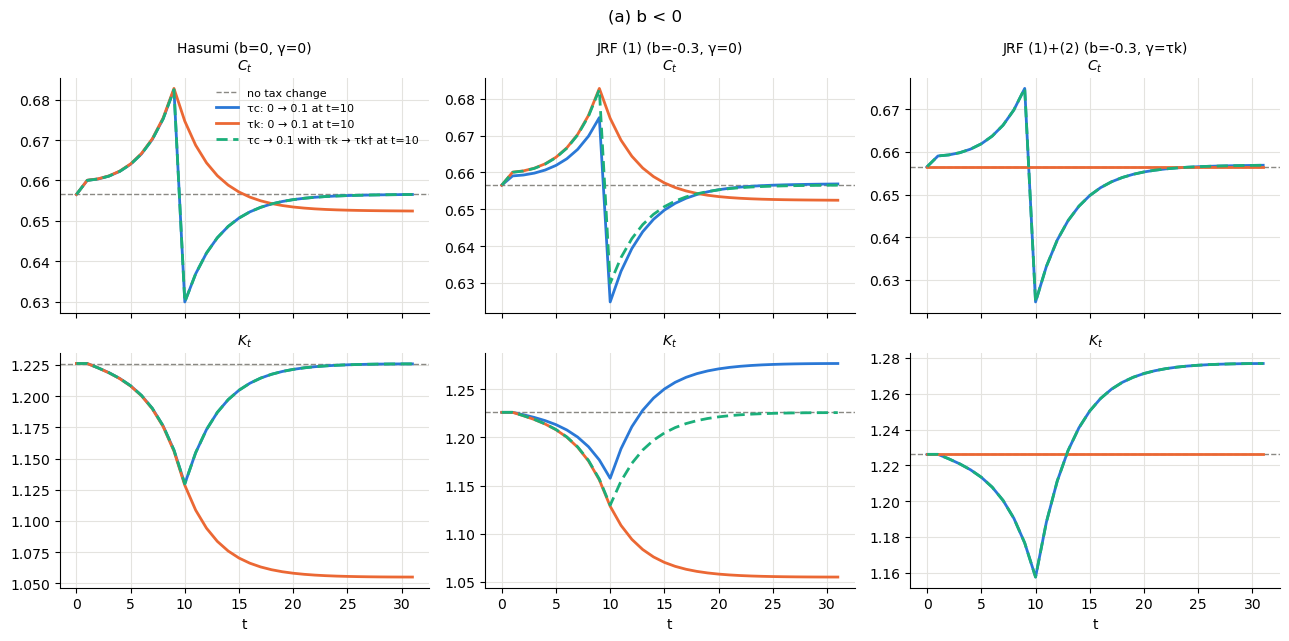

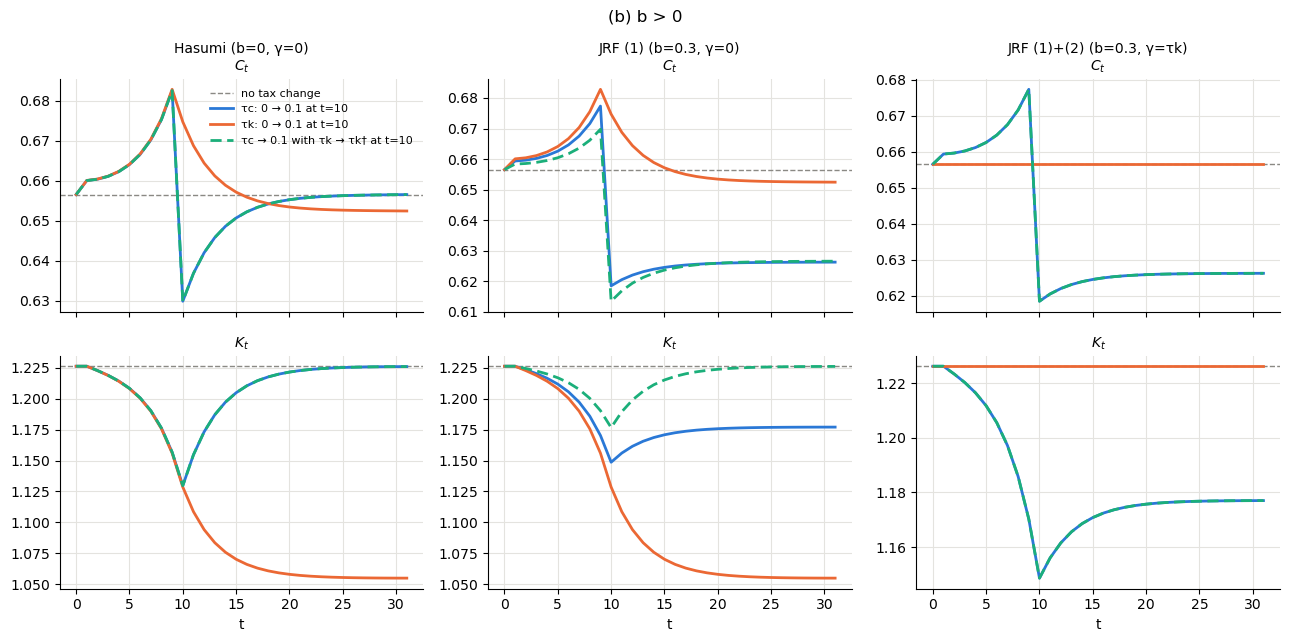

model                          policy         τk       C*       K*  welfare CE (%)
Hasumi (b=0, γ=0)              tc         0.0000   0.6565   1.2259          -0.006
Hasumi (b=0, γ=0)              tk         0.1000   0.6524   1.0550          -0.322
Hasumi (b=0, γ=0)              tc+tk†     0.0000   0.6565   1.2259          -0.006
JRF (1) (b=-0.3, γ=0)          tc         0.0000   0.6569   1.2769          -0.028
JRF (1) (b=-0.3, γ=0)          tk         0.1000   0.6524   1.0550          -0.322
JRF (1) (b=-0.3, γ=0)          tc+tk†     0.0282   0.6565   1.2259          -0.006
JRF (1)+(2) (b=-0.3, γ=τk)     tc         0.0000   0.6569   1.2769          -0.028
JRF (1)+(2) (b=-0.3, γ=τk)     tk         0.1000   0.6565   1.2261           0.000
JRF (1)+(2) (b=-0.3, γ=τk)     tc+tk†     0.0000   0.6569   1.2769          -0.028
JRF (1) (b=0.3, γ=0)           tc         0.0000   0.6263   1.1770          -4.119
JRF (1) (b=0.3, γ=0)           tk         0.1000   0.6524   1.0550          -0.322
JRF 

In [13]:
T = 30
groups = {
    "(a) b < 0": [("Hasumi (b=0, γ=0)", 0.0, False),
                  ("JRF (1) (b=-0.3, γ=0)", -0.3, False),
                  ("JRF (1)+(2) (b=-0.3, γ=τk)", -0.3, True)],
    "(b) b > 0": [("Hasumi (b=0, γ=0)", 0.0, False),
                  ("JRF (1) (b=0.3, γ=0)", 0.3, False),
                  ("JRF (1)+(2) (b=0.3, γ=τk)", 0.3, True)],
}

def tk_dagger(tc, b, gflag):
    # 基準 A: (1 - τk + γ) / (1+τc)^b = 1。γ = τk のときは τk によらないので、資本税はそのまま 0 とする
    return 0.0 if gflag else 1 - (1 + tc) ** b

paths = {}
for gname, cases in groups.items():
    for name, b, gflag in cases:
        for pol in ["none", "tc", "tk", "tc+tk†"]:
            tc = np.zeros(T + 2); tk = np.zeros(T + 2)
            if pol in ("tc", "tc+tk†"): tc[10:] = 0.1
            if pol == "tk": tk[10:] = 0.1
            if pol == "tc+tk†": tk[10:] = tk_dagger(0.1, b, gflag)
            gam = tk.copy() if gflag else np.zeros(T + 2)
            paths[name, pol] = transition(tc, tk, gam, b, T, wedge=(b < 0))

tt = np.arange(T + 2)
for gname, cases in groups.items():
    fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
    fig.suptitle(gname, fontsize=12)
    for j, (name, b, gflag) in enumerate(cases):
        for i, var in enumerate(["C", "K"]):
            ax = axes[i, j]
            base = paths[name, "none"][i]
            ax.axhline(base[0], color="#8a8984", lw=1, ls="--", label="no tax change")
            ax.plot(tt, paths[name, "tc"][i], color=COL[0], label="τc: 0 → 0.1 at t=10")
            ax.plot(tt, paths[name, "tk"][i], color=COL[1], label="τk: 0 → 0.1 at t=10")
            ax.plot(tt, paths[name, "tc+tk†"][i], color=COL[2], ls=(0, (4, 2)),
                    label="τc → 0.1 with τk → τk† at t=10")
            ax.set_title(f"{name}\n${var}_t$" if i == 0 else f"${var}_t$", fontsize=10)
            if i == 1: ax.set_xlabel("t")
    axes[0, 0].legend(fontsize=8, frameon=False)
    fig.tight_layout()
    plt.show()

print(f"{'model':30s} {'policy':8s} {'τk':>8s} {'C*':>8s} {'K*':>8s} {'welfare CE (%)':>15s}")
seen = set()
for gname, cases in groups.items():
    for name, b, gflag in cases:
        if name in seen: continue
        seen.add(name)
        W0 = welfare(paths[name, "none"][0])
        for pol in ["tc", "tk", "tc+tk†"]:
            C, K = paths[name, pol]
            tkv = {"tc": 0.0, "tk": 0.1, "tc+tk†": tk_dagger(0.1, b, gflag)}[pol]
            print(f"{name:30s} {pol:8s} {tkv:8.4f} {C[-1]:8.4f} {K[-1]:8.4f} {ce(welfare(C), W0):15.3f}")

蓮見モデル(各図の左列)では、$\tau_c$ の引き上げは「駆け込み」の一時的な変動を生むだけで、定常状態は変わらない。
一方、$\tau_k$ は $K^{\ast}$ と $C^{\ast}$ を下げる。これが本の結論である。
蓮見モデルでは $\tau_k^\dagger = 0$ なので、三本目の線は $\tau_c$ だけの線と重なる。

**(a) $b<0$**:JRF (1)(中列)では、消費税の引き上げで資本の私的収益が上がり、$K$ が修正黄金律を超えて**増える**(過剰蓄積)。
定常消費 $C^{\ast}$ はほとんど変わらないが、移行期に消費を削って資本を積むので、生涯厚生は下がる。
消費税と同時に資本税を $\tau_k^\dagger = 1-(1.1)^{-0.3} \approx 0.028$ だけ上げると(三本目の線)、$K^{\ast}$ は元の水準に戻り、厚生の損失はほぼ「駆け込み」の分だけになる。
**消費税を上げるなら、それとからめて資本課税も上げるべき**、という JRF の本来の主張が、移行経路の上でも確かめられる。
JRF (1)+(2)(右列)では、資本課税は経路に影響しない一方、消費税は過剰蓄積を生む。
資本税収がすべて公共投資で戻るので、資本税では楔を動かせず、三本目の線は $\tau_c$ だけの線と重なる。

なお、$b<0$ では消費税を上げると資本が増え、定常消費 $C^{\ast}$ もわずかに増える(修正黄金律は超えるが、消費が最大になる黄金律 $K \approx 1.297$ にはまだ届かないため)。
定常状態だけを見れば「消費税で資本も消費も増えた」と見える。「消費税は貯蓄と投資を促し、成長に良い」という論拠は、$b<0$ の世界では文字どおり正しい。
本稿はそれを否定するのではなく、そこに資本税も一定あった方がよい、と言うだけである。
しかしその資本は、移行期に人間の消費を削って積み上げたものであり、割引して見ると割に合わない。生涯厚生は下がる。
同じ効果を、成長(資本の水準)で評価するか、人間の生涯の消費で評価するかの違いであり、本稿は後者を採る。
これは、資本(AI)の蓄積を最優先すれば人間の消費の余地が削られる、という JRF の問題意識そのものである。
(このモデルには技術進歩がないので、ここでの「成長」は資本の水準が一段上がることであり、持続的な成長率の上昇ではない。)

**(b) $b>0$**:JRF (1)(中列)では、消費税も $K^{\ast}, C^{\ast}$ を下げる。$b=0.3$ では、その影響は資本課税より大きい。
三本目の線は $\tau_k^\dagger \approx -0.029$(資本補助)で $K^{\ast}$ を元の水準に戻すが、生産性の実物の損失は残る。
$C^{\ast}$ はほとんど戻らず、生涯厚生は $\tau_c$ だけの場合よりむしろわずかに悪化する(表)。
資本補助は資本を増やすだけで、失われた生産性を取り戻さないからである。
これが第 5 節の「帳簿の付け方では消えない楔」であり、$b>0$ では基準 A より基準 B(資本課税は正)の方が意味を持つ理由でもある。
JRF (1)+(2)(右列)では、資本課税は経路に何の影響も与えず、消費税だけが厚生を下げる。**結論が逆転する。**
右列の三本目の線は、(a) と同じ理由で $\tau_c$ だけの線と重なる。

(表の $K^{\ast}$ は $T+1=31$ 期の値。R ソースと同じく $C_{T+1}$ だけを定常値に固定しているため、定常値と小数第 4 位で差が出ることがある。)

ただし、この比較は税収が同じではない($\tau_c = 0.1$ と $\tau_k = 0.1$ では税収が違う)。
そこで次に、税収を中立にして最適な組合せを求める。

### 6.2 税収中立な最適税率の組合せ

定常状態の税収 $R = \tau_c C^{\ast} + \tau_k r^{\ast} K^{\ast}$ を一定($R = 0.05$、GDP の約 5%)に保つ。
各 $\tau_k$ に対し、これを満たす $\tau_c$ を求める。
$t=1$ から恒久的に税制を変えた場合の生涯厚生を、$\tau_k$ の関数として描き、最大化する。
ここでは $\gamma = 0$ とする($\gamma=\tau_k$ だと資本税収は還元されて財源にならない)。
これが基準 B(第 4 節)である。$b<0$ は私的収益の楔として入れる。
図には $-0.1 \le b \le 0.1$ だけを描く($|b| = 0.3$ は表のみ)。
表には、比較のため基準 A の $\tau_k^\dagger = 1-(1+\tau_c^{\ast})^b$ も並べる。

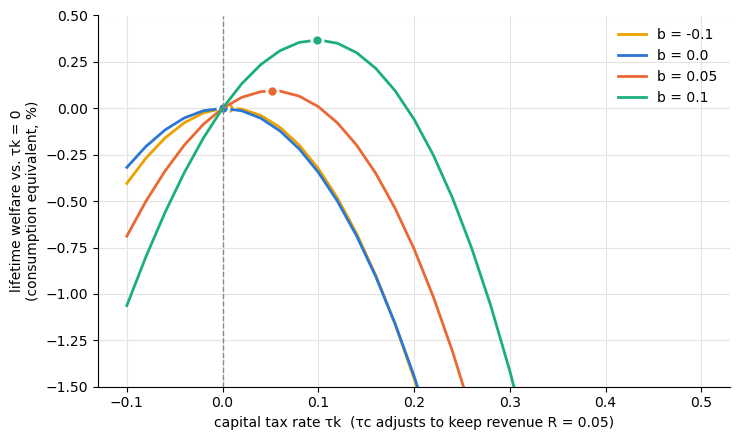

     b   τk* (B)      τc*   gain vs τk=0 (%CE)   τk† (A)
 -0.30    0.0192   0.0668               0.0162    0.0192
 -0.10    0.0070   0.0728               0.0018    0.0070
  0.00   -0.0000   0.0762              -0.0000    0.0000
  0.05    0.0518   0.0520               0.0950   -0.0025
  0.10    0.0987   0.0308               0.3687   -0.0030
  0.30    0.2486  -0.0327               3.0062    0.0099


In [14]:
T_long = 150
R = 0.05

def ss_revenue(tc, tk, b):
    C, K = steady(tk, tc, 0.0, b, wedge=(b < 0))
    Ae, _ = tech(tc, b, wedge=(b < 0))
    return tc * C + tk * alpha * float(Ae) * K ** alpha

def tc_for(tk, b):
    return scipy.optimize.brentq(lambda x: ss_revenue(x, tk, b) - R, -0.5, 3.0)

def lifetime(tk, b):
    tc0 = tc_for(tk, b)
    tc = np.full(T_long + 2, tc0); tk_ = np.full(T_long + 2, tk)
    tc[0] = 0.0; tk_[0] = 0.0          # t=0 は税のない旧定常状態
    C, K = transition(tc, tk_, np.zeros(T_long + 2), b, T_long, wedge=(b < 0))
    return welfare(C), tc0

bs = [-0.3, -0.1, 0.0, 0.05, 0.1, 0.3]
plotted = {-0.1: COL[3], 0.0: COL[0], 0.05: COL[1], 0.1: COL[2]}
grid = np.linspace(-0.1, 0.5, 31)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
rows = []
for b in bs:
    W_ref, _ = lifetime(0.0, b)
    ws = np.array([lifetime(x, b)[0] for x in grid])
    i = int(np.argmax(ws))
    res = scipy.optimize.minimize_scalar(lambda x: -lifetime(x, b)[0],
                                         bounds=(grid[max(i - 1, 0)], grid[min(i + 1, len(grid) - 1)]),
                                         method="bounded")
    Wopt, tcopt = lifetime(res.x, b)
    rows.append((b, res.x, tcopt, ce(Wopt, W_ref), 1 - (1 + tcopt) ** b))
    if b not in plotted:
        continue  # |b| = 0.3 は縦軸のスケールが大きく違うので表のみ
    ax.plot(grid, ce(ws, W_ref), color=plotted[b], label=f"b = {b}")
    ax.plot([res.x], [ce(Wopt, W_ref)], "o", color=plotted[b], ms=8, mec="white", mew=2)
ax.axvline(0, color="#8a8984", lw=1, ls="--")
ax.set_xlabel("capital tax rate τk  (τc adjusts to keep revenue R = 0.05)")
ax.set_ylabel("lifetime welfare vs. τk = 0\n(consumption equivalent, %)")
ax.set_ylim(-1.5, 0.5)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

print(f"{'b':>6s} {'τk* (B)':>9s} {'τc*':>8s} {'gain vs τk=0 (%CE)':>20s} {'τk† (A)':>9s}")
for b, tk_opt, tc_opt, gain, tk_dag in rows:
    print(f"{b:6.2f} {tk_opt:9.4f} {tc_opt:8.4f} {gain:20.4f} {tk_dag:9.4f}")

* $b=0$(蓮見モデル)では、生涯厚生を最大にする資本税率は $\tau_k^{\ast} \approx 0$ である。
  税収は消費税ですべて賄うのが最適で、Chamley–Judd の結論が数値的にも再現される。
* $b<0$ では、基準 B の最適値 $\tau_k^{\ast}$ は正で、基準 A の $\tau_k^\dagger$ とほぼ一致する。
  過剰蓄積の楔を資本課税で打ち消すのが最適であり、Lean の `optimal_capital_tax_pos_of_neg_b` を数値で裏付けている。
  値そのものは小さい($b=-0.1$ で約 0.7%)ので、図では $\tau_k = 0$ のすぐ右に頂点がある。
* $b>0$ では、基準 A の $\tau_k^\dagger$ は負(資本補助)だが、基準 B の最適値は $\tau_k^{\ast} > 0$ となる。
  消費税にも実物のコストがあるので、資本課税と消費税を組み合わせるのが最適になる。
  興味深いことに、この較正では $b$ が小さいとき $\tau_k^{\ast} \approx b$ となっている。
* $b = 0.3$ では $\tau_c^{\ast} < 0$(消費補助)まで行く。そのため表の $\tau_k^\dagger$ も、$\tau_c^{\ast}<0$ を代入した結果として正になっている。
  これは (1) の定式化が、消費税と実効生産性を対称に結び付けているためである。
  JRF の (1) にも単純化された恣意性があることを示している。
  それでも「$\tau_k=0$ はモデルの付け方次第で最適でなくなる」という本稿の論点は変わらない。

### 6.3 楔定理の数値確認

Lean の `optimal_capital_tax` が示すように、$\tau_k^\dagger = 1 + \gamma - (1+\tau_c)^b$ と置けば、
$(\tau_c, \gamma, b)$ が何であれ、定常資本はラムゼイ・モデルの修正黄金律 $K_R$ に一致するはずである。

In [15]:
_, K_R = steady(0.0, 0.0, 0.0, 0.0)
print(f"Ramsey (2.28) modified golden rule: K_R = {K_R:.6f}")
for tc, gam, b in [(0.1, 0.0, 0.0), (0.1, 0.0, -0.3), (0.2, 0.0, -0.3), (0.1, 0.0, 0.3),
                   (0.1, 0.05, 0.3), (0.2, 0.1, 0.3), (0.1, 0.1, 1.0)]:
    tk_dag = 1 + gam - (1 + tc) ** b
    _, K = steady(tk_dag, tc, gam, b)
    print(f"τc={tc:4.2f} γ={gam:4.2f} b={b:3.1f}  ->  τk† = {tk_dag:+.4f},  K* = {K:.6f}")

Ramsey (2.28) modified golden rule: K_R = 1.226145
τc=0.10 γ=0.00 b=0.0  ->  τk† = +0.0000,  K* = 1.226145
τc=0.10 γ=0.00 b=-0.3  ->  τk† = +0.0282,  K* = 1.226145
τc=0.20 γ=0.00 b=-0.3  ->  τk† = +0.0532,  K* = 1.226145
τc=0.10 γ=0.00 b=0.3  ->  τk† = -0.0290,  K* = 1.226145
τc=0.10 γ=0.05 b=0.3  ->  τk† = +0.0210,  K* = 1.226145
τc=0.20 γ=0.10 b=0.3  ->  τk† = +0.0438,  K* = 1.226145
τc=0.10 γ=0.10 b=1.0  ->  τk† = +0.0000,  K* = 1.226145


### 6.4 食料品減税の数値例

消費の割合 $s_f = 0.3$ を食料品、残りをその他とする。二つの場合を並べる。

* $b>0$:$b_f = 0.3$(食料品)、$b_o = 0.05$(その他)。生産関数に入れる。
* $b<0$:$b_f = -0.3$、$b_o = -0.05$。私的収益の楔として入れる。

これらは例示であり、推定値ではない。
定常状態の消費税収 $R = (s_f\tau_f + (1-s_f)\tau_o)\,C^{\ast}$ を、一律税率のときと同じ $R = 0.05$ に保つ。
そのうえで食料品の税率 $\tau_f$ を下げ、その他の税率 $\tau_o$ で埋め合わせる。
$t=1$ から恒久的に税制を変えた場合の生涯厚生を、一律税率のときと比べる($\tau_k = 0$, $\gamma = 0$)。

In [16]:
s_f = 0.3

def disc2(tf, to, b_f, b_o):
    # 消費税による割引 D = (1+τf)^b_f (1+τo)^b_o
    return (1 + tf) ** b_f * (1 + to) ** b_o

def steady_2(Ae, m):
    # 実効生産性 Ae, 私的収益の倍率 m のときの定常状態
    K = (rho / (m * alpha * Ae)) ** (1 / (alpha - 1))
    return Ae * K ** alpha - delta * K - g, K

def tech2(tf, to, b_f, b_o):
    D = disc2(tf, to, b_f, b_o)
    return (A / D, 1.0) if b_f > 0 else (A, 1.0 / D)   # b>0: 生産関数 / b<0: 私的収益の楔

def food_revenue(tf, to, b_f, b_o):
    C, K = steady_2(*tech2(tf, to, b_f, b_o))
    return (s_f * tf + (1 - s_f) * to) * C

def lifetime_2(Ae1, m1, T=150):
    # t=0 は税のない定常状態。t>=1 で (Ae, m) が (Ae1, m1) に変わる(税率一定なので消費税の比はオイラー方程式で消える)
    C0, K0 = steady_2(A, 1.0); CT, KT = steady_2(Ae1, m1)
    Ae = np.full(T + 2, Ae1); Ae[0] = A
    def resid(X):
        C = np.concatenate([[C0], X[:T], [CT]]); K = np.concatenate([[K0, K0], X[T:]])
        t = np.arange(1, T + 1)
        euler = C[t + 1] / C[t] - beta * (m1 * alpha * Ae[t + 1] * K[t + 1] ** (alpha - 1) - delta + 1)
        resource = K[t + 1] - (Ae[t] * K[t] ** alpha + (1 - delta) * K[t] - C[t] - g)
        return np.concatenate([euler, resource])
    lam = 0.75 ** np.arange(1, T + 1)
    sol = scipy.optimize.root(resid, np.concatenate([CT + (C0 - CT) * lam, KT + (K0 - KT) * lam]), method="hybr")
    assert sol.success and np.max(np.abs(sol.fun)) < 1e-6
    return welfare(np.concatenate([[C0], sol.x[:T], [CT]]))

_, K_R = steady_2(A, 1.0)
print(f"Ramsey (2.28) modified golden rule: K_R = {K_R:.4f}")
for b_f, b_o in [(0.3, 0.05), (-0.3, -0.05)]:
    print(f"\nb_f = {b_f}, b_o = {b_o}")
    t_uni = scipy.optimize.brentq(lambda x: food_revenue(x, x, b_f, b_o) - R, 0.0, 1.0)
    W_uni = lifetime_2(*tech2(t_uni, t_uni, b_f, b_o))
    print(f"{'τf':>7s} {'τo':>7s} {'K*':>8s} {'C*':>8s} {'welfare vs uniform (%CE)':>26s} {'τk† (γ=0)':>10s}")
    for tf in [t_uni, 0.06, 0.04, 0.02, 0.0]:
        to = scipy.optimize.brentq(lambda x: food_revenue(tf, x, b_f, b_o) - R, -0.5, 3.0)
        Ae1, m1 = tech2(tf, to, b_f, b_o)
        C, K = steady_2(Ae1, m1)
        tk_dag = 1 - disc2(tf, to, b_f, b_o)
        print(f"{tf:7.4f} {to:7.4f} {K:8.4f} {C:8.4f} {ce(lifetime_2(Ae1, m1), W_uni):26.3f} {tk_dag:10.4f}")

Ramsey (2.28) modified golden rule: K_R = 1.2261

b_f = 0.3, b_o = 0.05
     τf      τo       K*       C*   welfare vs uniform (%CE)  τk† (γ=0)
 0.0796  0.0796   1.1801   0.6281                      0.000    -0.0272
 0.0600  0.0870   1.1888   0.6335                      0.834    -0.0219
 0.0400  0.0946   1.1979   0.6391                      1.709    -0.0164
 0.0200  0.1022   1.2074   0.6449                      2.609    -0.0109
 0.0000  0.1097   1.2171   0.6509                      3.536    -0.0052

b_f = -0.3, b_o = -0.05
     τf      τo       K*       C*   welfare vs uniform (%CE)  τk† (γ=0)
 0.0761  0.0761   1.2720   0.6568                     -0.000     0.0254
 0.0600  0.0830   1.2643   0.6568                      0.007     0.0212
 0.0400  0.0916   1.2548   0.6568                      0.013     0.0160


 0.0200  0.1002   1.2451   0.6567                      0.018     0.0107


 0.0000  0.1088   1.2352   0.6566                      0.021     0.0051


* $b>0$:食料品の税率を下げてその他で埋め合わせるほど、$K^{\ast}$ が修正黄金律 $K_R$ に向かって**上がり**、$C^{\ast}$ と生涯厚生も上がる。
* $b<0$:食料品減税で、過剰蓄積していた $K^{\ast}$ が $K_R$ に向かって**下がる**。$C^{\ast}$ はほとんど変わらないが、生涯厚生は上がる。
  必要な資本税率 $\tau_k^\dagger$ も下がる(`food_tax_cut_lowers_required_capital_tax`)。
  $b<0$ の効果が小さいのは、修正黄金律の近くでは過剰蓄積の厚生損失が二次の大きさにしかならないためである。
* どちらの場合も、食料品減税は $K^{\ast}$ をラムゼイの値に近づける(`food_tax_cut_toward_ramsey_pos`, `food_tax_cut_toward_ramsey_neg`)。
  定理は課税ベースが等しい場合を扱ったが、この数値例は課税ベースが異なる(食料品 30%、その他 70%)場合でも同じ方向になることを示している。
* 効果の大きさは $b_f$ と $b_o$ の差に応じて変わるので、数字そのものより方向に意味がある。
  また $b<0$ では定常消費 $C^{\ast}$ がほとんど動かないので、定常状態だけでなく生涯厚生で比べる必要がある。

## 7. 結論

1. 蓮見モデル(Chamley–Judd 型の財政モデル)では、資本課税ゼロ・消費税で賄うのが最適である。これは Lean で証明でき(§1–§2)、生涯厚生の数値計算でも再現できる(6.2 節, $b=0$)。
   ただしその理由は、非弾力的な労働供給のもとで一定の消費税が**一括税**になるからにすぎない。
2. JRF の変形を入れるとこの結論は崩れる。(1) 消費税が資本の収益を変えること($b \ne 0$)、(2) 公共投資が資本の持ち主に戻ること、の二つである。
   ラムゼイ配分を再現する資本税率は $\tau_k^\dagger = 1+\gamma-(1+\tau_c)^b$ となり、消費税と公共投資に連動して決まる。
   $b<0$ なら $\gamma=0$ でも正で、消費税とともに増える(§3、Lean)。$b>0$ でも、税収中立の生涯厚生では正になり(6.2 節)、
   公共投資が十分なら基準 A でも正になる。$\gamma=\tau_k$ では結論が逆転し、消費税の引き上げが厚生を悪化させる(§3、Lean)。
   $b$ の符号は確定しないが、**どちらの符号でも、資本課税ゼロは一般には最適でない。**
3. 消費税の中でも、必需品への課税ほど $|b|$ が大きいなら、**食料品減税は $b$ の符号にかかわらず $K^{\ast}$ をラムゼイの値に近づける**
   (§3 `food_tax_cut_toward_ramsey_pos`, `food_tax_cut_toward_ramsey_neg`、6.4 節)。$b<0$ では、必要な資本税率も下げる。
   食料品の軽減税率には、再分配とは別に、資本蓄積上の理由がある。これはスミスやリカードの「必需品への課税は利潤と蓄積に効く」の現代版である。
4. 予算制約 (3.2) に政府支出 $g_t$ を足し戻すと、税は恒等的に消え、ラムゼイ・モデル (2.28) に戻る(§4、Lean)。
   Chamley–Judd の長期目標そのものが、このラムゼイ・モデルの修正黄金律である。
   (1)(2) を入れても税の楔は同じ操作で消えるが、$b>0$ の実物の損失だけは残る(`back_to_ramsey_general`)。
5. したがって、Chamley–Judd の結論の本体は「**長期的には楔を消せ**」であり、「**資本税をゼロにせよ**」ではない。
   どの税が楔を生むかは、税と還元を家計がどう認識するかという帳簿の付け方で決まり、真の世界(ラムゼイ・モデル)からは決まらない。
   JRF の (2) が恣意的なら、蓮見モデルの (3.2) も同じ程度に恣意的である。
   「資本課税ゼロが望ましい」という主張は、その恣意的な選択に依存した結論にすぎない。
   同じことは JRF の本来の主張($b<0$ で資本課税が正)にも当てはまり、本稿はそれを隠さない。
   帳簿の付け方で消える楔は還元の制度設計で消せるが、$b>0$ の実物の損失は課税ベースや税率構成を変えるしかない(第 5 節)。
6. JRF の当初の問題意識は、AI という資本の蓄積を最優先すれば人間の消費の余地が削られる、というものだった。
   本稿の結果は、少なくとも「効率性の理論が資本課税ゼロを要求する」という反論は、その問題意識を退ける根拠にならないことを示している。
   自動化資本への課税は、最適課税論の主流でもすでに論じられている(Guerreiro–Rebelo–Teles 2022; Costinot–Werning 2023)。

**限界と今後の課題**(Claude による注記):

* 本稿の Lean 証明は、定常状態と、予算制約 (3.2) からの二期間の変分によるオイラー方程式の導出までである。無限期間の和 (3.1) や、移行過程を含む最適課税問題(ラムゼイ問題)そのものは形式化しておらず、生涯厚生については数値計算に頼った。
* 労働供給を内生化すると消費税は労働を歪める。その場合の比較(Atkinson–Stiglitz, Chamley の原モデル)は扱っていない。
* (1) の $b$ の符号と大きさ($b_f, b_o$)や (2) の $\gamma$ の大きさは実証的に詰めていない。(1) の仕組み(硬直性、非課税の資本サービス、蓄積の動機)はいずれもモデルの外にある。
* $b<0$ の側で食料品減税が有効という結論は、$|b_f| > |b_o|$ を支える賃金圧力の経路 (c) に依存している。(a)(b) が主なら逆の結論になりうる。
* 本稿の $b>0$ の結論(税収中立のもとで資本課税が正)は、それが**実物の損失**であることに依存する。
  $b>0$ を私的収益の楔として読むと(消費税が、税収を生まない資本所得税として働く場合。たとえば将来の増税の見込み)、
  差し引きの資本税率 $\tau_k - \gamma$ の最適値は $1-(1+\tau_c)^b < 0$、つまり資本補助になる。
  これは、資本税 $\tau_k$ を取ったうえで、それ以上を公共投資として資本の持ち主に戻す($\gamma > \tau_k$)形に相当し、
  JRF (2022) の「国費から $\tau_k r_t K_t$ よりも大きい $\gamma_t r_t K_t$ が公共投資された」という設定そのものである。
  総額の資本税率は正でありうるが、それは資本税で公共投資を賄う制度設計の正当化であって、資本の蓄積を抑える根拠にはならない。
* 6.4 節のパラメータ($b_f, b_o$、食料品の割合)は例示であり、推定値ではない。
* 文献上も、異質な家計・不完備市場(Aiyagari 1995)、ライフサイクル(Conesa–Kitao–Krueger 2009)、
  効用の形状(Lansing 1999; Straub–Werning 2020)によって、長期の最適資本課税は正になりうることが知られている。
  本稿の議論は、代表的家計という Chamley–Judd の土俵の中でも「ゼロ」が頑健でないことを示した点に位置付けられる。

## 付録: Lean による一括検証

ここまでの `%%writefile` セルで `CJ_formula.lean` が出来上がっている。以下で Lean 4 (v4.34.1) + Mathlib (v4.34.1) をそろえ、まとめて検証する。

* **Colab**:elan をインストールし、`cjlean/` に Mathlib を依存に持つ Lake プロジェクトを作る。
  `lake exe cache get` でビルド済みの .olean を取得する(初回は数分)。
* **ローカル**:カレントディレクトリにすでに Mathlib 入りの `lakefile.lean` があれば、それをそのまま使う。

本稿のファイルは Mathlib だけに依存し、1 回検証すれば済む。
そのため、`--incr-header-save` / `--incr-load` によるスナップショットは使わず、`lake env lean` を 1 回走らせる。
途中で何度も検証したい場合は、ヘッダ(`import Mathlib`)のスナップショットを保存すると 2 回目以降が速くなる。

In [17]:
%%bash
set -e
export PATH="$HOME/.elan/bin:$PATH"
if [ -f lakefile.lean ] && grep -q mathlib lakefile.lean; then
  echo "using the existing Lake project in the current directory"
  echo "." > .leandir
else
  if ! command -v lake >/dev/null 2>&1; then
    curl -sSfL https://raw.githubusercontent.com/leanprover/elan/master/elan-init.sh \
      | sh -s -- -y --default-toolchain none
  fi
  mkdir -p cjlean && cd cjlean
  echo 'leanprover/lean4:v4.34.1' > lean-toolchain
  cat > lakefile.lean <<'EOF'
import Lake
open Lake DSL

package cjlean

require mathlib from git
  "https://github.com/leanprover-community/mathlib4.git" @ "v4.34.1"
EOF
  lake update 2>&1 | tail -3
  lake exe cache get 2>&1 | tail -3
  cd ..
  echo "cjlean" > .leandir
fi

using the existing Lake project in the current directory


In [18]:
%%bash
export PATH="$HOME/.elan/bin:$PATH"
LEANDIR=$(cat .leandir)
FILE=$(pwd)/CJ_formula.lean
cd "$LEANDIR"
time lake env lean "$FILE" && echo "=== CJ_formula.lean: all theorems checked ==="

'CJ.Params.cj_core' depends on axioms: [propext, Classical.choice, Quot.sound]
'CJ.Params.euler_from

_budget' depends on axioms: [propext, Classical.choice, Quot.sound]
'CJ.Params.ramsey_euler_from_bud

get' depends on axioms: [propext, Classical.choice, Quot.sound]
'CJ.Params.hasumi_capital_tax_harmfu

l' depends on axioms: [propext, Classical.choice, Quot.sound]
'CJ.Params.jrf_reversal' depends on ax

ioms: [propext, Classical.choice, Quot.sound]
'CJ.Params.optimal_capital_tax' depends on axioms: [pr

...

ioms: [propext, Classical.choice, Quot.sound]
'CJ.Params.back_to_ramsey_general' depends on axioms: 

[propext, Classical.choice, Quot.sound]
'CJ.Params.back_to_ramsey' depends on axioms: [propext, Clas

sical.choice, Quot.sound]



real	0m3.638s
user	0m7.152s
sys	0m1.177s


=== CJ_formula.lean: all theorems checked ===
